# Giai đoạn 1: Khám phá & Kiểm kê Cấp độ Bộ dữ liệu (Hồi 1 — Bối cảnh)

## 00. Giới thiệu giai đoạn

- **Tên giai đoạn:** Giai đoạn 1 — Khám phá & Kiểm kê cấp độ bộ dữ liệu (`01_dataset_discovery.ipynb`).
- **Vai trò trong câu chuyện dữ liệu (Hồi 1 — *Bối cảnh*):** Thiết lập bức tranh toàn cảnh về **14 doanh nghiệp Việt Nam không đồng nhất** (`dev_001`–`dev_014`) trong phân vùng `public_test`, làm căn cứ minh bạch để chọn tập doanh nghiệp đại diện ở Giai đoạn 2 và xác định phạm vi đối chiếu hợp lệ ở Giai đoạn 3.
- **Mục tiêu:**
  1. Thiết lập đọc dữ liệu chỉ đọc (read-only) từ `data/public_test/` hoặc `raw_data/public_test/`, chặn tuyệt đối `train` và `questions.jsonl`.
  2. Kiểm kê đầy đủ siêu dữ liệu từ 14 tệp `README.md`, cấu trúc tệp (`.csv`, `.xlsx`, `.sqlite`), số lượng bản ghi và độ phủ thời gian (`min_date`–`max_date`, khoảng trống).
  3. Suy luận và kiểm chứng ngành nghề (`industry`), gắn nhãn mức độ chi tiết (`granularity`) và dựng bộ biểu đồ Giải thích cho Hồi 1.
- **Phạm vi dữ liệu:** Chỉ sử dụng 14 thư mục `dev_001`–`dev_014`, `rulebook.md` và `calendar.csv` thuộc `public_test`.
- **Đầu ra mong đợi (Cột mốc M1) & Nơi lưu trữ:**
  - Thư mục gốc phase: `artifacts/guided_eda/phase1_dataset_discovery/`
  - Bảng kết quả (`PHASE1_TABLES_DIR`): `tables/readme_metadata.csv`, `tables/objects_inventory.csv`, `tables/file_inventory.csv`, `tables/temporal_coverage.csv`, `tables/industry_classification.csv`, `tables/catalog_14.csv`.
  - Biểu đồ Hồi 1 (`PHASE1_FIGURES_DIR`): `figures/` (các ảnh tĩnh từ `T1.3a` và `T1.3b`).
- **Các giới hạn cần tuân thủ:**
  - Không sửa đổi dữ liệu gốc; không sử dụng dữ liệu `train` hay `questions.jsonl`.
  - Không dùng ML/DL, dự báo, phân cụm, PCA/t-SNE/UMAP, Plotly hoặc Folium.
  - Không cộng gộp số dòng ở các mức chi tiết khác nhau (ví dụ: dòng hàng với hóa đơn) thành "số giao dịch".
  - Không mặc định khoảng thời gian thiếu dữ liệu là có giá trị bằng `0`.


## 01. Thiết lập môi trường


In [1]:
import sys
from pathlib import Path

# Tự động xác định thư mục gốc dự án và thêm src vào sys.path
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src" / "common").is_dir():
    for parent in PROJECT_ROOT.parents:
        if (parent / "src" / "common").is_dir():
            PROJECT_ROOT = parent
            break

SCRIPT_ROOT = PROJECT_ROOT / "src"
if not SCRIPT_ROOT.is_dir():
    raise FileNotFoundError(
        f"Không tìm thấy thư mục mã nguồn EDA tại: {SCRIPT_ROOT}"
    )

if str(SCRIPT_ROOT) not in sys.path:
    sys.path.insert(0, str(SCRIPT_ROOT))

print(f"Thư mục gốc dự án : {PROJECT_ROOT}")
print(f"Thư mục script EDA : {SCRIPT_ROOT}")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import có chọn lọc các tiện ích nền tảng và kiểm kê từ src/
from common.config import load_config
from common.paths import (
    DatasetContext,
    assert_not_in_raw,
    assert_safe_output,
    is_benchmark_file,
    resolve_source,
)
from readers.markdown_reader import (
    extract_bullets,
    extract_table_rules,
    read_business_readme,
    read_rulebook,
)
from readers.csv_reader import inspect_csv, read_all_csv_rows
from readers.excel_reader import inspect_workbook_fast, list_sheets, read_sheet_rows
from readers.sqlite_reader import inspect_sqlite, query_readonly
from inventory.file_manifest import build_file_manifest, classify_source_type
from inventory.sheet_registry import build_sheet_registry
from inventory.sqlite_registry import build_sqlite_registry
from temporal.date_fields import detect_event_role, missing_periods, profile_date_fields
from temporal.coverage import daily_counts_from_dates, profile_time_coverage
from temporal.calendar_registry import validate_calendar

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

# Thiết lập giao diện biểu đồ cơ bản (hỗ trợ hiển thị inline trong Jupyter)
# Lưu ý: Không import visualization.figure_theme vì module đó ép backend Agg.
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titlelocation": "left",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.linestyle": ":",
    "grid.alpha": 0.55,
    "axes.unicode_minus": False,
    "figure.figsize": (10, 5.5),
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

# Bảng màu gợi ý theo nguyên tắc "Bắt đầu từ màu xám" (Schwabish)
COLOR_GRAY = "#9AA5B1"
COLOR_GRAY_DARK = "#52606D"
COLOR_ACCENT_BLUE = "#1769AA"
COLOR_ACCENT_TEAL = "#087B5A"
COLOR_ACCENT_AMBER = "#A36516"
COLOR_ACCENT_RED = "#B32336"


Thư mục gốc dự án : C:\Users\teteb\Desktop\pythoncode\data-visualization-uth
Thư mục script EDA : C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\src


## 02. Đọc dữ liệu & Khởi tạo thư mục đầu ra


In [2]:
# Khởi tạo cấu hình và ngữ cảnh chỉ đọc cho phân vùng public_test
config = load_config(workspace_root=PROJECT_ROOT)
context: DatasetContext = config.context_for("public_test")

# Kiểm tra các điều kiện tiên quyết về nguồn dữ liệu và phạm vi an toàn
assert context.read_only is True, "Ngữ cảnh dữ liệu phải ở chế độ chỉ đọc (read_only=True)."
assert context.root.is_dir(), f"Không tìm thấy thư mục public_test: {context.root}"
assert context.rulebook_path.is_file(), f"Thiếu rulebook.md tại: {context.rulebook_path}"
assert context.calendar_path.is_file(), f"Thiếu calendar.csv tại: {context.calendar_path}"

business_ids = context.business_ids()
assert len(business_ids) == 14, f"Kỳ vọng 14 doanh nghiệp nhưng tìm thấy {len(business_ids)}: {business_ids}"

# Xác nhận cơ chế nhận diện và chặn đọc questions.jsonl
questions_candidate = context.root / "questions.jsonl"
assert is_benchmark_file(questions_candidate), "Hàm is_benchmark_file phải chặn được questions.jsonl."

# Khởi tạo (mkdir) thư mục lưu trữ đầu ra cho Giai đoạn 1 (nằm ngoài data/ và raw_data/)
GUIDED_ROOT = config.output_root / "guided_eda"
PHASE1_ROOT = GUIDED_ROOT / "phase1_dataset_discovery"
PHASE1_TABLES_DIR = PHASE1_ROOT / "tables"
PHASE1_FIGURES_DIR = PHASE1_ROOT / "figures"

assert_not_in_raw(config.raw_root, GUIDED_ROOT)
for target_dir in (PHASE1_ROOT, PHASE1_TABLES_DIR, PHASE1_FIGURES_DIR):
    assert_safe_output(config.output_root, target_dir)
    target_dir.mkdir(parents=True, exist_ok=True)

print(f"Đường dẫn public_test : {context.root}")
print(f"Chế độ chỉ đọc        : {context.read_only}")
print(f"Số doanh nghiệp       : {len(business_ids)} ({business_ids[0]} .. {business_ids[-1]})")
print(f"Tệp rulebook          : {context.rulebook_path.name} (tồn tại)")
print(f"Tệp lịch âm/dương     : {context.calendar_path.name} (tồn tại)")
print(f"Chặn questions.jsonl  : {is_benchmark_file(questions_candidate)} (đã khóa đọc)")
print(f"Thư mục bảng Phase 1  : {PHASE1_TABLES_DIR}")
print(f"Thư mục hình Phase 1  : {PHASE1_FIGURES_DIR}")


Đường dẫn public_test : C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\data\public_test
Chế độ chỉ đọc        : True
Số doanh nghiệp       : 14 (dev_001 .. dev_014)
Tệp rulebook          : rulebook.md (tồn tại)
Tệp lịch âm/dương     : calendar.csv (tồn tại)
Chặn questions.jsonl  : True (đã khóa đọc)
Thư mục bảng Phase 1  : C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\artifacts\guided_eda\phase1_dataset_discovery\tables
Thư mục hình Phase 1  : C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\artifacts\guided_eda\phase1_dataset_discovery\figures


In [3]:
import inspect
print(context.root)
print(sorted(p.name for p in context.root.iterdir()))
print(inspect.getsource(type(context).business_ids))

C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\data\public_test
['calendar.csv', 'data', 'questions.jsonl', 'rulebook.md']
    def business_ids(self) -> list[str]:
        if not self.business_root.exists():
            return []
        return sorted(path.name for path in self.business_root.iterdir() if path.is_dir())



In [4]:
print(context.business_root)
print(context.business_root.exists())

C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\data\public_test\data
True


## 03. Tổng quan dữ liệu cơ bản


In [5]:
# Kiểm tra tổng quan calendar.csv và xem mẫu cấu trúc của 1 doanh nghiệp đầu tiên
calendar_info = validate_calendar(context.calendar_path, split="public_test")
print(
    f"Lịch calendar.csv: {calendar_info.row_count} ngày "
    f"({calendar_info.min_date} -> {calendar_info.max_date}), trạng thái={calendar_info.status}"
)
print(f"Các cửa sổ Tết trong lịch: {calendar_info.tet_windows}")

# Xem mẫu 1 doanh nghiệp đầu tiên để kiểm tra cách hoạt động của các hàm đọc
sample_biz_id = business_ids[0]
sample_biz_dir = context.business_root_path(sample_biz_id)
sample_files = sorted(p.name for p in sample_biz_dir.iterdir() if p.is_file())
print(f"\nDoanh nghiệp mẫu ({sample_biz_id}) gồm {len(sample_files)} tệp: {sample_files}")

sample_readme_path = sample_biz_dir / "README.md"
if sample_readme_path.is_file():
    sample_doc = read_business_readme(sample_readme_path)
    print(f"Tiêu đề README: {sample_doc.title} ({sample_doc.line_count} dòng)")
    print("Các đề mục trong README:", [b.heading_text for b in sample_doc.blocks if b.heading_text])

# Xem cấu trúc 1 tệp Excel mẫu của doanh nghiệp đầu tiên
sample_xlsx = next((sample_biz_dir / f for f in sample_files if f.lower().endswith(".xlsx")), None)
if sample_xlsx is not None:
    sheets = list_sheets(sample_xlsx)
    print(f"Danh sách sheet trong '{sample_xlsx.name}': {sheets}")
    first_sheet_name = sheets[0][0]
    hdr, sample_rows = read_sheet_rows(sample_xlsx, first_sheet_name, max_rows=3)
    print(f"Cột trong sheet '{first_sheet_name}' ({len(hdr)} cột): {hdr}")
    display(pd.DataFrame(sample_rows))


Lịch calendar.csv: 1461 ngày (2024-01-01 -> 2027-12-31), trạng thái=PASS
Các cửa sổ Tết trong lịch: (('2024-02-02', '2024-02-19'), ('2025-01-22', '2025-02-07'), ('2026-02-10', '2026-02-26'), ('2027-01-30', '2027-02-15'))

Doanh nghiệp mẫu (dev_001) gồm 3 tệp: ['Danh sách hàng hóa.xlsx', 'README.md', 'So_chi_tiet_ban_hang.xlsx']
Tiêu đề README: Dữ liệu dev_001 (108 dòng)
Các đề mục trong README: ['Dữ liệu dev_001', 'File', 'Cột trong `So_chi_tiet_ban_hang.xlsx`', 'Cột trong `Danh sách hàng hóa.xlsx`', 'Quy ước']
Danh sách sheet trong 'Danh sách hàng hóa.xlsx': [('Sheet1', 'visible')]
Cột trong sheet 'Sheet1' (19 cột): ('Vị trí', 'Mã hàng hóa', 'Định mức tồn tối đa', 'Được bán trực tiếp', 'Ghi chú', 'Thuộc tính', 'Tên hàng hóa', 'Mã barcode', 'Mô tả sản phẩm', 'Mã HH Liên quan', 'Bảo hành', 'Nhóm hàng hóa', 'Đơn vị tính', 'Trọng lượng', 'Định mức tồn tối thiểu', 'Mẫu ghi chú', 'Giá bán', 'Hình ảnh', 'Giá vốn')


,Vị trí,Mã hàng hóa,Định mức tồn tối đa,Được bán trực tiếp,Ghi chú,Thuộc tính,Tên hàng hóa,Mã barcode,Mô tả sản phẩm,Mã HH Liên quan,Bảo hành,Nhóm hàng hóa,Đơn vị tính,Trọng lượng,Định mức tồn tối thiểu,Mẫu ghi chú,Giá bán,Hình ảnh,Giá vốn
0,None,SP0001,999999999,1,None,None,Coca Cola 330ml,8936254610875,None,None,None,nước giải khát,lon,None,0,None,"10,000.0000",None,"8,377.0000"
1,None,SP0002,999999999,1,None,None,Pepsi 330ml,8935497051209,None,None,None,nước giải khát,lon,None,0,None,"10,000.0000",None,"8,753.0000"
2,None,SP0003,999999999,1,None,None,Sting dâu 330ml,8938829398904,None,None,None,nước giải khát,chai,None,0,None,"10,000.0000",None,"8,574.0000"


## 04. Các tác vụ khám phá dữ liệu (EDA Tasks)


## Tác vụ T1.0 — Xác minh cấu hình chỉ đọc `public_test` và cơ chế chặn phạm vi

### Mục tiêu
Đảm bảo mọi thao tác đọc dữ liệu trong suốt Giai đoạn 1 chỉ diễn ra trên phân vùng `public_test` ở chế độ chỉ đọc, đồng thời thiết lập hàm bảo vệ không đọc nhầm `train` hay `questions.jsonl`.

### Câu hỏi khám phá
- Đường dẫn thực tế của bộ dữ liệu đang nằm ở `data/public_test/` hay `raw_data/public_test/`?
- Toàn bộ 14 doanh nghiệp (`dev_001`–`dev_014`), `rulebook.md` và `calendar.csv` đều đọc được nguyên vẹn?
- Cơ chế lọc/chặn tệp benchmark (`questions.jsonl`) và phân vùng `train` hoạt động ra sao?

### Các bước thực hiện

**Bước 1 — Xác minh cấu hình nguồn & chế độ chỉ đọc**
Kiểm tra các thuộc tính của đối tượng `config` và `context` (đặc biệt `config.splits`, `context.read_only`, `context.root`).

**Bước 2 — Kiểm tra tính đầy đủ của 14 thư mục doanh nghiệp và tệp tham chiếu**
Duyệt qua từng mã trong `business_ids`, kiểm tra sự tồn tại của thư mục con và tệp `README.md` (nếu có).

**Bước 3 — Viết hàm bảo vệ chặn `questions.jsonl` và `train`**
Định nghĩa một hàm helper `assert_safe_public_test_path(path)` kiểm tra `not is_benchmark_file(path)` và không nằm trong `train` trước khi mở bất kỳ tệp nào.

### Gợi ý phương pháp & Lưu ý
- Kiểm tra `config.splits` xem có đúng chỉ chứa `('public_test',)` hay không.
- Hàm `is_benchmark_file(path)` trong `common.paths` đã lọc sẵn `questions.jsonl` và `answers.jsonl`; có thể kết hợp kiểm tra `'train' not in path.parts`.
- Không chỉnh sửa hoặc ghi bất kỳ tệp tạm nào vào bên trong `context.root`.

### Triển khai


In [6]:
print("Splits cấu hình :", config.splits)
print("public_test root:", context.root)
print("business_root   :", context.business_root)
print("read_only       :", context.read_only)

Splits cấu hình : ('public_test',)
public_test root: C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\data\public_test
business_root   : C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\data\public_test\data
read_only       : True


In [7]:
rows = []
for biz_id in business_ids:
    biz_path = context.business_root_path(biz_id)
    files = [p for p in biz_path.iterdir() if p.is_file()]
    rows.append({
        "business_id": biz_id,
        "n_files": len(files),
        "has_readme": (biz_path / "README.md").is_file(),
    })
check_df = pd.DataFrame(rows)
display(check_df)
assert check_df["has_readme"].all(), "Có doanh nghiệp thiếu README.md"

,business_id,n_files,has_readme
0,dev_001,3,True
1,dev_002,19,True
2,dev_003,8,True
3,dev_004,8,True
4,dev_005,24,True
5,dev_006,2,True
6,dev_007,4,True
7,dev_008,5,True
8,dev_009,2,True
9,dev_010,6,True


In [8]:
def assert_safe_public_test_path(path: Path) -> Path:
    p = Path(path).resolve()
    assert not is_benchmark_file(p), f"Chặn tệp benchmark: {p}"
    assert "train" not in p.parts, f"Chặn phân vùng train: {p}"
    root = context.root.resolve()
    assert root == p or root in p.parents, f"Nằm ngoài public_test: {p}"
    return p

# Tự kiểm thử: các lệnh này PHẢI bị chặn
for bad in [context.root / "questions.jsonl", context.root / "train" / "x.csv"]:
    try:
        assert_safe_public_test_path(bad)
        print("LỖI: không chặn được", bad)
    except AssertionError as e:
        print("Đã chặn đúng:", bad.name)

Đã chặn đúng: questions.jsonl
Đã chặn đúng: x.csv


### Kết quả & Nhận định

> **TODO (T1.0):** Thành viên tự ghi nhận phát hiện dựa trên bằng chứng vừa chạy ở trên (không suy diễn vượt quá dữ liệu).

- **Xác nhận vị trí thư mục `public_test` thực tế trên máy và danh sách 14 thư mục doanh nghiệp:** ...
- **Trạng thái kiểm tra rào chắn không đọc `train` và `questions.jsonl`:** ...


## Tác vụ T1.1a — Đọc toàn bộ 14 tệp `README.md` và tổng hợp siêu dữ liệu mô tả

### Mục tiêu
Đọc toàn bộ 14 tệp `README.md` của `dev_001`–`dev_014` để trích xuất hình thức ghi nhận dữ liệu, ngày kết thúc dữ liệu (cutoff), các quy ước đơn vị tính, bảng `Ghi tắt` và mô tả cấu trúc bảng.

### Câu hỏi khám phá
- Doanh nghiệp nào có `README.md` mô tả đầy đủ các bảng, cột và quy ước? Doanh nghiệp nào mô tả ngắn hoặc thiếu thông tin?
- Các hình thức ghi nhận dữ liệu được đề cập trong `README.md` gồm những loại nào (sổ tay Excel, phần mềm bán hàng/POS, nhiều tệp theo tháng, CSDL SQLite)?
- Ngày cutoff (`dữ liệu có đến hết...`) và các quy ước đặc thù (quy đổi đơn vị, `Ghi tắt`, ca làm việc) của từng doanh nghiệp là gì?

### Các bước thực hiện

**Bước 1 — Duyệt và đọc nội dung 14 tệp `README.md`**
Sử dụng `read_business_readme(path)` hoặc đọc trực tiếp văn bản từng tệp `README.md` của 14 doanh nghiệp.

**Bước 2 — Khám phá cấu trúc các đề mục và bảng trong từng `README.md`**
Kiểm tra các `block.heading_text`, danh sách gạch đầu dòng (`extract_bullets`) và bảng Markdown (`block.table_rows`) có trong mỗi README.

**Bước 3 — Trích xuất các trường metadata cốt lõi**
Với mỗi doanh nghiệp, trích xuất: nguồn/hình thức ghi nhận, danh sách tệp được mô tả, ngày cutoff (nếu ghi), có quy ước đơn vị không, có bảng `Ghi tắt` không.

**Bước 4 — Tổng hợp thành `readme_metadata_df` và lưu vào `PHASE1_TABLES_DIR`**
Chuyển kết quả thành DataFrame `readme_metadata_df`, đối chiếu với danh sách tệp thực tế và lưu tại `PHASE1_TABLES_DIR / 'readme_metadata.csv'`.

### Gợi ý phương pháp & Lưu ý
- Mỗi đối tượng trả về bởi `read_business_readme(path)` là `MarkdownDocument` gồm thuộc tính `.title`, `.line_count` và `.blocks` (mỗi block có `.heading_text`, `.body`, `.table_rows`).
- Nên kết hợp đọc văn bản gốc của từng README thay vì chỉ dựa vào regex cứng, vì cách trình bày giữa các doanh nghiệp có thể khác nhau.
- Chú ý phân biệt quy ước về *ngày cutoff*, *đơn vị quy đổi* và *mã ghi tắt* — đây là đầu vào quan trọng cho `T1.1c` và `T2.2b`.

### Triển khai


In [9]:
manifest = build_file_manifest(context)
manifest_df = pd.DataFrame([r.to_dict() for r in manifest.records])

# Chỉ lấy 14 doanh nghiệp, bỏ calendar.csv / rulebook.md ở cấp split
biz_df = manifest_df[manifest_df["business_id"] != "__split__"].copy()

# Tách README khỏi tệp dữ liệu
biz_df["is_readme"] = biz_df["logical_path"].str.endswith("README.md")
data_files_df = biz_df[~biz_df["is_readme"] & biz_df["source_type"].isin(["csv", "xlsx", "sqlite"])].copy()
data_files_df["file_name"] = data_files_df["logical_path"].str.split("/").str[-1]
data_files_df["size_mb"] = (data_files_df["size_bytes"] / 1024**2).round(3)

print("Tổng tệp trong manifest 14 doanh nghiệp:", len(biz_df))
print("Tệp dữ liệu (csv/xlsx/sqlite):", len(data_files_df))
print("Số README:", int(biz_df["is_readme"].sum()))
print("Tệp bị bỏ qua:", manifest.ignored_paths)

summary = (
    data_files_df.pivot_table(index="business_id", columns="source_type",
                              values="file_name", aggfunc="count", fill_value=0)
    .join(data_files_df.groupby("business_id")["size_mb"].sum().rename("size_mb"))
)
display(summary)

Tổng tệp trong manifest 14 doanh nghiệp: 94
Tệp dữ liệu (csv/xlsx/sqlite): 80
Số README: 14
Tệp bị bỏ qua: ('questions.jsonl',)


,csv,sqlite,xlsx,size_mb
business_id,,,,
dev_001,0,0,2,4.386
dev_002,0,0,18,3.842
dev_003,1,0,6,13.986
dev_004,0,0,7,2.985
dev_005,0,0,23,4.930
dev_006,0,1,0,20.109
dev_007,3,0,0,23.933
dev_008,0,0,4,20.523
dev_009,1,0,0,1.543


In [10]:
readme_docs = {}
readme_text = {}
for biz in business_ids:
    p = assert_safe_public_test_path(context.business_root_path(biz) / "README.md")
    if p.is_file():
        readme_docs[biz] = read_business_readme(p)
        readme_text[biz] = p.read_text(encoding="utf-8")
print("Đọc được", len(readme_docs), "/ 14 README | thiếu:", [b for b in business_ids if b not in readme_docs])

Đọc được 14 / 14 README | thiếu: []


In [11]:
import re
CUTOFF_KW = re.compile(r"(đến hết|có đến|đến ngày|cutoff|hết ngày)", re.I)
for biz, doc in readme_docs.items():
    print(f"== {biz} | {doc.line_count} dòng | đề mục:", [b.heading_text for b in doc.blocks if b.heading_text])
    for line in readme_text[biz].splitlines():
        if CUTOFF_KW.search(line):
            print("   >>", line.strip()[:200])

== dev_001 | 108 dòng | đề mục: ['Dữ liệu dev_001', 'File', 'Cột trong `So_chi_tiet_ban_hang.xlsx`', 'Cột trong `Danh sách hàng hóa.xlsx`', 'Quy ước']
   >> - Dữ liệu có đến hết 08/07/2026.
== dev_002 | 31 dòng | đề mục: ['Dữ liệu dev_002', 'File', 'Cột trong `BanHang_T<tháng>_<năm>.xlsx`, sheet `DonHang_ChiTiet`', 'Cột trong `DanhSachQuyDoi.xlsx`', 'Quy ước']
   >> - Dữ liệu có đến hết 24/05/2026.
== dev_003 | 24 dòng | đề mục: ['Dữ liệu dev_003', 'File', 'Quy ước']
   >> - Dữ liệu có đến hết 21/08/2026.
   >> - **Công nợ**: mỗi lần khách trả tiền cho một đơn là một dòng, **Tiền thu** là số tiền trả lần đó; **Tổng thanh toán** là số khách phải trả cho cả đơn; **Công nợ** là số tiền của đơn chưa thu, tính đế
== dev_004 | 79 dòng | đề mục: ['Dữ liệu dev_004', 'File', 'Cột trong `SoBanHang.xlsx`', 'Cột trong `DanhMuc.xlsx`', 'Cột trong `TonKho.xlsx`', 'Cột trong `SoGiaoHang.xlsx`', 'Cột trong `SoHanNo.xlsx`', 'Cột trong `SoNhapHang.xlsx`', 'Cột trong `BangGia.xlsx`', 'Quy ước']
   >> - D

In [12]:
DATE_PATS = [
    (re.compile(r"(\d{4})-(\d{2})-(\d{2})"), lambda m: f"{m[1]}-{m[2]}-{m[3]}"),
    (re.compile(r"(\d{1,2})/(\d{1,2})/(\d{4})"), lambda m: f"{m[3]}-{int(m[2]):02d}-{int(m[1]):02d}"),
]
FILE_PAT = re.compile(r"`([^`]+\.(?:xlsx|csv|sqlite))`", re.I)

def find_cutoff(text):
    fallback = None
    for line in text.splitlines():
        if CUTOFF_KW.search(line):
            fallback = fallback or line.strip()
            for pat, fmt in DATE_PATS:
                m = pat.search(line)
                if m:
                    return fmt(m), line.strip()
    return None, fallback

readme_records = []
actual_files = data_files_df.groupby("business_id")["file_name"].apply(set).to_dict()
for biz, doc in readme_docs.items():
    text = readme_text[biz]
    low = text.lower()
    cutoff_date, cutoff_line = find_cutoff(text)
    described = sorted(set(FILE_PAT.findall(text)))
    actual = actual_files.get(biz, set())
    readme_records.append({
        "business_id": biz,
        "readme_title": doc.title,
        "readme_line_count": doc.line_count,
        "n_sections": sum(1 for b in doc.blocks if b.heading_text),
        "n_bullets": len(extract_bullets(doc)),
        "n_table_rows": sum(len(b.table_rows) for b in doc.blocks),
        "readme_cutoff_date": cutoff_date,
        "readme_cutoff_text": cutoff_line,
        "has_unit_conversion": bool(re.search(r"quy đổi|đơn vị", low)),
        "has_ghi_tat": "ghi tắt" in low,
        "has_shift_note": bool(re.search(r"\bca\b|ca làm", low)),
        "files_described_n": len(described),
        "files_actual_n": len(actual),
        "files_not_described": " | ".join(sorted(actual - set(described))),
    })

In [13]:
readme_metadata_df = pd.DataFrame(readme_records)
readme_metadata_df.to_csv(PHASE1_TABLES_DIR / "readme_metadata.csv", index=False, encoding="utf-8-sig")
display(readme_metadata_df.drop(columns=["readme_cutoff_text"]))
print("Chưa bắt được cutoff:", readme_metadata_df.loc[readme_metadata_df.readme_cutoff_date.isna(), "business_id"].tolist())

,business_id,readme_title,readme_line_count,n_sections,n_bullets,n_table_rows,readme_cutoff_date,has_unit_conversion,has_ghi_tat,has_shift_note,files_described_n,files_actual_n,files_not_described
0,dev_001,Dữ liệu dev_001,108,5,97,0,2026-07-08,True,False,False,2,2,
1,dev_002,Dữ liệu dev_002,31,5,18,0,2026-05-24,True,False,False,4,18,BanHang_T10_2025.xlsx | BanHang_T11_2025.xlsx | BanHang_T12_2025.xlsx | BanHang_T1_2026.xlsx | BanHang_T2_2025.xlsx ...
2,dev_003,Dữ liệu dev_003,24,3,15,0,2026-08-21,True,False,True,7,7,
3,dev_004,Dữ liệu dev_004,79,10,58,0,2026-06-10,True,False,False,7,7,
4,dev_005,Dữ liệu dev_005,66,10,43,0,2026-05-10,True,False,False,9,23,BanHang_Thang01_2026.xlsx | BanHang_Thang02_2025.xlsx | BanHang_Thang02_2026.xlsx | BanHang_Thang03_2025.xlsx | BanH...
5,dev_006,Dữ liệu dev_006,24,4,12,0,2026-08-08,True,False,True,1,1,
6,dev_007,Dữ liệu dev_007,82,6,69,0,2026-09-19,True,False,False,3,3,
7,dev_008,Dữ liệu dev_008,119,7,104,0,2026-07-22,True,False,False,4,4,
8,dev_009,Dữ liệu dev_009,20,4,11,0,2026-06-24,False,False,False,1,1,
9,dev_010,Dữ liệu dev_010,80,8,63,0,2026-09-06,True,False,False,5,5,


Chưa bắt được cutoff: []


### Trực quan hóa


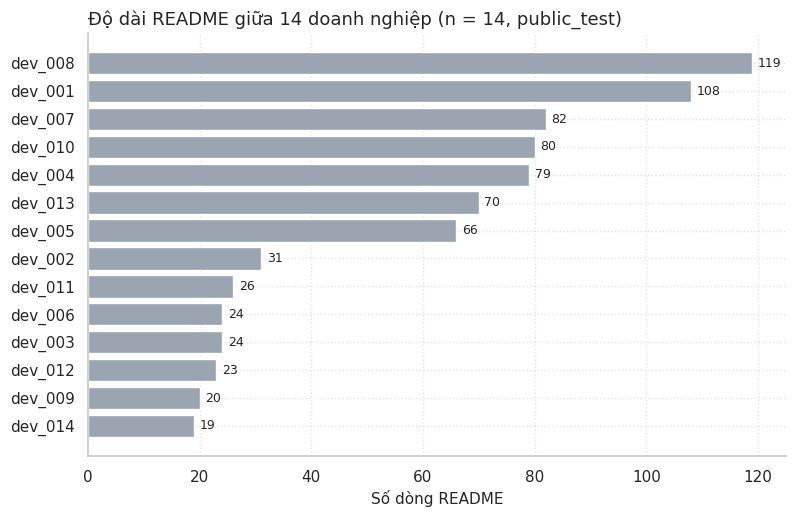

In [14]:
d = readme_metadata_df.sort_values("readme_line_count")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(d["business_id"], d["readme_line_count"], color=COLOR_GRAY)
ax.set_xlabel("Số dòng README")
ax.set_title("Độ dài README giữa 14 doanh nghiệp (n = 14, public_test)")
for y, v in enumerate(d["readme_line_count"]):
    ax.text(v + 1, y, str(v), va="center", fontsize=9)
fig.savefig(PHASE1_FIGURES_DIR / "readme_length.png")
plt.show()

### Kết quả & Nhận định

> **TODO (T1.1a):** Thành viên tự ghi nhận phát hiện dựa trên bằng chứng vừa chạy ở trên (không suy diễn vượt quá dữ liệu).

- **Tổng hợp các hình thức ghi nhận dữ liệu xuất hiện trong 14 `README.md`:** ...
- **Danh sách các doanh nghiệp có quy ước đặc biệt (`Ghi tắt`, quy đổi đơn vị, tách tệp theo tháng, cutoff):** ...
- **Các điểm chưa rõ hoặc cần kiểm chứng lại ở `T1.1b`:** ...


## Tác vụ T1.1b — Quét toàn bộ tệp `.csv`, `.xlsx` (mọi sheet) và `.sqlite` của 14 doanh nghiệp

### Mục tiêu
Kiểm kê chính xác ở cấp độ tệp, sheet và bảng CSDL trên toàn bộ 14 doanh nghiệp: định dạng tệp, dung lượng, tên bảng/sheet (kể cả sheet ẩn nếu có), danh sách cột và số dòng.

### Câu hỏi khám phá
- 14 doanh nghiệp sử dụng các định dạng tệp nào? Phân bố số lượng tệp, số sheet và số bảng SQLite theo từng doanh nghiệp ra sao?
- Có tệp Excel nào chứa nhiều sheet (tách theo tháng hoặc tách theo nghiệp vụ), sheet ẩn, ô gộp (`merged_cells`) hay công thức chưa?
- Quy mô số dòng dữ liệu giữa các doanh nghiệp chênh lệch nhau bao nhiêu bậc độ lớn?

### Các bước thực hiện

**Bước 1 — Kiểm kê danh sách tệp nguồn của 14 doanh nghiệp**
Quét toàn bộ tệp dữ liệu (`.csv`, `.xlsx`, `.sqlite`) trong 14 thư mục (hoặc đối chiếu với `build_file_manifest(context)`), phân biệt rõ tệp dữ liệu với tệp tài liệu `README.md`.

**Bước 2 — Quét chi tiết các tệp `.csv`**
Dùng `inspect_csv(path)` để kiểm tra encoding, delimiter, header, số dòng dữ liệu (`data_row_count`) và các cảnh báo (dòng trống, tiêu đề lặp, BOM...).

**Bước 3 — Quét toàn bộ sheet trong các tệp `.xlsx`**
Dùng `inspect_workbook_fast(path)` (hoặc `build_sheet_registry(...)`) để lấy tên sheet, trạng thái `sheet_state`, header, số dòng, cảnh báo `merged_ranges_present` / `formula_cells_present`.

**Bước 4 — Quét cấu trúc các bảng/view trong tệp `.sqlite`**
Dùng `inspect_sqlite(path)` để liệt kê danh sách bảng/view, tên cột, khóa chính, khóa ngoại và số dòng từng bảng.

**Bước 5 — Tổng hợp bảng cấu trúc tệp & quy mô dòng vào `PHASE1_TABLES_DIR`**
Tổng hợp thành `objects_inventory_df` (lưu `PHASE1_TABLES_DIR / 'objects_inventory.csv'`) và `file_inventory_df` (lưu `PHASE1_TABLES_DIR / 'file_inventory.csv'`).

### Gợi ý phương pháp & Lưu ý
- Hàm `build_file_manifest(context)` trả về `FileManifest` gồm cả tệp cấp split (`business_id == '__split__'`). Khi thống kê 14 doanh nghiệp, nhớ lọc `business_id != '__split__'` và tách riêng `README.md`.
- Cẩn thận với `row_count`: một số bảng là danh mục sản phẩm/khách hàng, một số bảng là chi tiết dòng hàng, một số bảng là hóa đơn. Ghi nhận riêng từng bảng trước khi tổng hợp.
- Một số tệp Excel có thể có dòng tiêu đề phụ hoặc nhiều header; kiểm tra `header_confidence` và xem mẫu vài dòng đầu khi cần.

### Triển khai


In [15]:
for st in ["csv", "xlsx", "sqlite"]:
    sub = data_files_df[data_files_df["source_type"] == st]
    if sub.empty:
        print(st, "-> không có file"); continue
    p = Path(sub.iloc[0]["absolute_path"])
    fn = {"csv": inspect_csv, "xlsx": inspect_workbook_fast, "sqlite": inspect_sqlite}[st]
    res = fn(p)
    print("====", st, p.name, "->", type(res))
    print(res if not hasattr(res, "__dict__") else vars(res))

==== csv ton_kho.csv -> <class 'readers.csv_reader.CsvInspection'>
{'path': WindowsPath('C:/Users/teteb/Desktop/pythoncode/data-visualization-uth/data/public_test/data/dev_003/ton_kho.csv'), 'encoding': 'utf-8-sig', 'delimiter': ',', 'header': ('Ton kho', 'ma_sp', 'ten_hang', 'ĐVT'), 'data_row_count': 50, 'total_row_count': 50, 'blank_row_count': 0, 'repeated_header_count': 0, 'ragged_row_count': 0, 'duplicate_header_count': 0, 'bom_present': True, 'warnings': ('utf8_bom_present',)}
==== xlsx Danh sách hàng hóa.xlsx -> <class 'list'>
[SheetInspection(path=WindowsPath('C:/Users/teteb/Desktop/pythoncode/data-visualization-uth/data/public_test/data/dev_001/Danh sách hàng hóa.xlsx'), sheet_name='Sheet1', sheet_state='visible', max_row=61, max_column=19, header=('Vị trí', 'Mã hàng hóa', 'Định mức tồn tối đa', 'Được bán trực tiếp', 'Ghi chú', 'Thuộc tính', 'Tên hàng hóa', 'Mã barcode', 'Mô tả sản phẩm', 'Mã HH Liên quan', 'Bảo hành', 'Nhóm hàng hóa', 'Đơn vị tính', 'Trọng lượng', 'Định mức t

In [16]:
errors = []
csv_objects = []
for r in data_files_df[data_files_df["source_type"] == "csv"].itertuples():
    try:
        ins = inspect_csv(Path(r.absolute_path))
        csv_objects.append({
            "business_id": r.business_id, "file_path": r.logical_path, "source_type": "csv",
            "object_name": r.file_name, "object_type": "csv_file", "state": "",
            "row_count": ins.data_row_count, "column_count": len(ins.header),
            "columns": " | ".join(map(str, ins.header)),
            "warnings": ";".join(ins.warnings),
        })
    except Exception as e:
        errors.append((r.logical_path, repr(e)))
print("CSV:", len(csv_objects), "tệp | lỗi:", len(errors))

CSV: 10 tệp | lỗi: 0


In [17]:
xlsx_objects = []
for r in data_files_df[data_files_df["source_type"] == "xlsx"].itertuples():
    try:
        for s in inspect_workbook_fast(Path(r.absolute_path)):
            warns = list(s.warnings)
            if s.merged_range_count: warns.append(f"merged_ranges={s.merged_range_count}")
            if s.formula_cell_count: warns.append(f"formula_cells={s.formula_cell_count}")
            if s.has_repeated_header: warns.append("repeated_header")
            xlsx_objects.append({
                "business_id": r.business_id, "file_path": r.logical_path, "source_type": "xlsx",
                "object_name": s.sheet_name, "object_type": "sheet", "state": s.sheet_state,
                "row_count": s.data_row_count, "column_count": len(s.header),
                "columns": " | ".join(map(str, s.header)),
                "warnings": ";".join(warns),
            })
    except Exception as e:
        errors.append((r.logical_path, repr(e)))
print("XLSX sheet:", len(xlsx_objects), "| lỗi tích lũy:", len(errors))

XLSX sheet: 136 | lỗi tích lũy: 0


In [18]:
sqlite_objects = []
for r in data_files_df[data_files_df["source_type"] == "sqlite"].itertuples():
    try:
        for o in inspect_sqlite(Path(r.absolute_path)):
            sqlite_objects.append({
                "business_id": r.business_id, "file_path": r.logical_path, "source_type": "sqlite",
                "object_name": o.name, "object_type": o.object_type, "state": "",
                "row_count": o.row_count, "column_count": o.column_count,
                "columns": " | ".join(c["name"] for c in o.columns),
                "warnings": "",
            })
    except Exception as e:
        errors.append((r.logical_path, repr(e)))
print("SQLite bảng/view:", len(sqlite_objects), "| lỗi tích lũy:", len(errors))
if errors:
    display(pd.DataFrame(errors, columns=["file", "error"]))

SQLite bảng/view: 17 | lỗi tích lũy: 0


In [19]:
objects_inventory_df = pd.DataFrame(csv_objects + xlsx_objects + sqlite_objects)

# Cấp tệp: số đối tượng và tổng số dòng bản ghi (mọi bảng cộng lại, KHÔNG phải số giao dịch)
file_inventory_df = (
    objects_inventory_df.groupby(["business_id", "file_path", "source_type"], as_index=False)
    .agg(n_objects=("object_name", "count"),
         total_record_rows=("row_count", "sum"),
         max_object_rows=("row_count", "max"))
    .merge(data_files_df[["logical_path", "size_mb"]].rename(columns={"logical_path": "file_path"}),
           on="file_path", how="left")
)

objects_inventory_df.to_csv(PHASE1_TABLES_DIR / "objects_inventory.csv", index=False, encoding="utf-8-sig")
file_inventory_df.to_csv(PHASE1_TABLES_DIR / "file_inventory.csv", index=False, encoding="utf-8-sig")

print("Đã lưu:", sorted(p.name for p in PHASE1_TABLES_DIR.iterdir()))

per_biz = (objects_inventory_df.groupby("business_id")
           .agg(n_files=("file_path", "nunique"), n_objects=("object_name", "count"),
                total_record_rows=("row_count", "sum"), max_object_rows=("row_count", "max")))
display(per_biz)

Đã lưu: ['catalog_14.csv', 'date_field_profiles.csv', 'file_inventory.csv', 'industry_classification.csv', 'objects_inventory.csv', 'readme_metadata.csv', 'temporal_coverage.csv']


,n_files,n_objects,total_record_rows,max_object_rows
business_id,,,,
dev_001,2,2,90914,90854
dev_002,18,18,85145,5652
dev_003,7,11,167828,62580
dev_004,7,24,65702,28398
dev_005,23,23,157721,77653
dev_006,1,17,302800,73901
dev_007,3,3,122859,121067
dev_008,4,4,155223,100000
dev_009,1,1,23338,23338


### Trực quan hóa


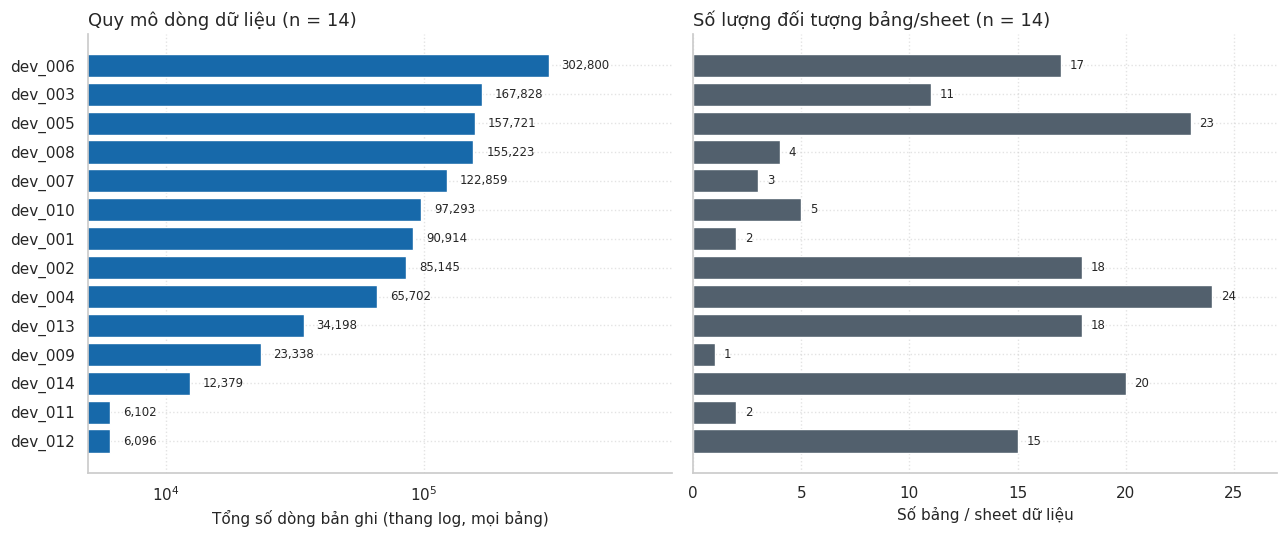

In [20]:
d_scale = per_biz.reset_index().sort_values("total_record_rows", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)

# Biểu đồ 1: Tổng số dòng dữ liệu (thang log do chênh lệch ~50 lần từ 6k đến 302k)
axes[0].barh(d_scale["business_id"], d_scale["total_record_rows"], color=COLOR_ACCENT_BLUE)
axes[0].set_xscale("log")
axes[0].set_xlabel("Tổng số dòng bản ghi (thang log, mọi bảng)")
axes[0].set_title("Quy mô dòng dữ liệu (n = 14)")
for y, v in enumerate(d_scale["total_record_rows"]):
    axes[0].text(v * 1.12, y, f"{v:,}", va="center", fontsize=8.5)
axes[0].set_xlim(right=d_scale["total_record_rows"].max() * 3)

# Biểu đồ 2: Số lượng bảng / sheet dữ liệu
axes[1].barh(d_scale["business_id"], d_scale["n_objects"], color=COLOR_GRAY_DARK)
axes[1].set_xlabel("Số bảng / sheet dữ liệu")
axes[1].set_title("Số lượng đối tượng bảng/sheet (n = 14)")
for y, v in enumerate(d_scale["n_objects"]):
    axes[1].text(v + 0.4, y, str(v), va="center", fontsize=8.5)
axes[1].set_xlim(0, d_scale["n_objects"].max() + 3)

fig.tight_layout()
fig.savefig(PHASE1_FIGURES_DIR / "inventory_scale_overview.png")
plt.show()


### Kết quả & Nhận định

> **TODO (T1.1b):** Thành viên tự ghi nhận phát hiện dựa trên bằng chứng vừa chạy ở trên (không suy diễn vượt quá dữ liệu).

- **Tổng số tệp dữ liệu, số sheet Excel và số bảng SQLite phát hiện được trên 14 doanh nghiệp:** ...
- **Các doanh nghiệp có cấu trúc nhiều tệp/nhiều sheet hoặc cảnh báo cấu trúc cần chú ý ở giai đoạn sau:** ...
- **Phạm vi chênh lệch quy mô dòng dữ liệu giữa các doanh nghiệp:** ...


## Tác vụ T1.1c — Trích xuất `min_date`, `max_date`, số ngày/tháng có dữ liệu và khoảng trống thời gian

### Mục tiêu
Xác định khoảng thời gian thực tế (`min_date`–`max_date`), mật độ ngày/tháng hoạt động và các khoảng trống dữ liệu của từng doanh nghiệp; đối chiếu với ngày cutoff được công bố trong `README.md`.

### Câu hỏi khám phá
- Mỗi doanh nghiệp bắt đầu và kết thúc ghi nhận dữ liệu vào ngày nào (cutoff rơi vào tháng mấy năm 2026)?
- Doanh nghiệp nào có dữ liệu liên tục, doanh nghiệp nào có tháng bị đứt quãng hoặc khoảng trống nhiều ngày?
- Có sự khác biệt nào giữa ngày giao dịch (`order`) với các mốc ngày khác (ngày giao, ngày thu tiền, hạn sử dụng) hay không?

### Các bước thực hiện

**Bước 1 — Nhận diện các cột biểu diễn ngày tháng/thời gian**
Từ danh sách cột ở `T1.1b`, xác định các cột có khả năng chứa ngày tháng và phân loại vai trò sự kiện (`detect_event_role(col)`).

**Bước 2 — Đọc và chuẩn hóa giá trị ngày tháng (không sửa tệp gốc)**
Kiểm tra định dạng ngày (ISO, `dd/mm/yyyy`, Excel serial date...) và đếm số giá trị lỗi parse (`parse_failure_n`).

**Bước 3 — Tính `min_date`, `max_date`, số ngày/tháng có dữ liệu và phát hiện khoảng trống**
Tính `min_date`, `max_date`, `active_days`, `span_days`, danh sách tháng không có bản ghi (`missing_periods`) cho từng doanh nghiệp.

**Bước 4 — Đối chiếu với cutoff trong `README.md` và lưu `temporal_coverage.csv`**
So sánh `max_date` quan sát được từ dữ liệu giao dịch chính với ngày cutoff nêu trong `README.md` và xuất ra `PHASE1_TABLES_DIR / 'temporal_coverage.csv'`.

### Gợi ý phương pháp & Lưu ý
- Không thay lẫn `hạn sử dụng` (expiry date) hay `ngày đăng ký` thành ngày hoạt động bán hàng (`order_date`). Hãy tách riêng hoặc ghi rõ cột ngày nào đại diện cho hoạt động chính.
- Cẩn thận định dạng ngày `dd/mm/yyyy` vs `mm/dd/yyyy` và số serial Excel.
- Nhớ quy tắc cốt lõi: *Thiếu bản ghi trong một tháng không đồng nghĩa doanh thu bằng 0* — cần ghi rõ là khoảng trống dữ liệu (`missing_months`).

### Triển khai


In [21]:
import sqlite3
import unicodedata
from datetime import date

from schema.type_inference import is_blank, parse_date, parse_datetime
from temporal.coverage import (
    daily_counts_from_dates,
    profile_time_coverage,
    weekday_counts_from_dates,
)
from temporal.date_fields import DateFieldProfile, profile_date_fields


def _norm(s: str) -> str:
    s = unicodedata.normalize("NFD", str(s).lower()).replace("đ", "d")
    s = "".join(c for c in s if not unicodedata.combining(c))
    return re.sub(r"[^a-z0-9]", "", s)


DATE_TOKENS = ("ngay", "date", "thoigian", "time", "taoluc", "hansudung", "handung")


def is_date_col(col: str) -> bool:
    n = _norm(col)
    return any(t in n for t in DATE_TOKENS) and "songay" not in n


def role_of(col: str) -> str:
    n = _norm(col)
    if "hansudung" in n or "handung" in n:
        return "expiry"
    if "apdung" in n:
        return "price_effective"
    if "giaodich" in n:
        return "sale"
    if "giao" in n:
        return "delivery"
    if "trahang" in n:
        return "return"
    if "nhap" in n:
        return "stock_or_purchase"
    if any(t in n for t in ("vaolam", "nhanviec", "thoiviec", "dangky", "khaitruong", "taoluc", "ngaytao", "sinh")):
        return "created"
    if any(t in n for t in ("thu", "tra", "thanhtoan", "gop", "ngaytt")):
        return "payment"
    return "sale"


# Cấu hình: business_id -> (regex tên file, regex tên sheet/bảng, tên cột ngày chính)
MAIN_DATE = {
    "dev_001": (r"So_chi_tiet_ban_hang", r".*", "Ngày"),
    "dev_002": (r"BanHang_T\d+_\d{4}", r"DonHang_ChiTiet", "Ngày đặt hàng"),
    "dev_003": (r"BanHang_TongHop", r"^BanHang$", "Ngày HĐ"),
    "dev_004": (r"SoBanHang", r"^T\d{2}-\d{4}$", "Thời gian"),
    "dev_005": (r"BanHang_Thang\d+_\d{4}", r"DonHang_ChiTiet", "Ngày đặt hàng"),
    "dev_006": (r"pos\.sqlite", r"^don_hang$", "ThoiGianLap"),
    "dev_007": (r"chi_tiet_hoa_don", r".*", "Ngày giao dịch"),
    "dev_008": (r"ChiTietHoaDon_\d", r".*", "Ngày xuất"),
    "dev_009": (r"danh_sach_hoa_don", r".*", "Ngày tháng"),
    "dev_010": (r"don_hang\.csv", r".*", "Date"),
    "dev_011": (r"SoBanHang", r"Sổ bán hàng", "Ngày"),
    "dev_012": (r"SoSuaXe", r"^T\d{1,2}-\d{4}$", "Ngày"),
    "dev_013": (r"BanHang_\d{4}", r"^T\d{2}-\d{4}$", "Ngày"),
    "dev_014": (r"SoBanHang", r".*", "Ngày"),
}

print("Đã nạp cấu hình MAIN_DATE cho", len(MAIN_DATE), "doanh nghiệp.")

Đã nạp cấu hình MAIN_DATE cho 14 doanh nghiệp.


In [22]:
def load_rows(path, st: str, obj: str, cols: list[str]) -> list[dict]:
    if st == "csv":
        df = pd.read_csv(
            path, dtype=str, encoding="utf-8-sig", keep_default_na=False,
            usecols=lambda c: c in cols
        )
        return df.to_dict("records")
    if st == "xlsx":
        _, rows = read_sheet_rows(path, obj, max_rows=None)
        return rows
    if st == "sqlite":
        con = sqlite3.connect(f"file:{path.as_posix()}?mode=ro", uri=True)
        try:
            cur = con.execute("SELECT " + ", ".join(f'"{c}"' for c in cols) + f' FROM "{obj}"')
            names = [d[0] for d in cur.description]
            return [dict(zip(names, r)) for r in cur]
        finally:
            con.close()
    return []


def to_dates(rows: list[dict], col: str) -> list[date]:
    out = []
    for r in rows:
        v = r.get(col)
        if is_blank(v):
            continue
        d = parse_date(v)
        if d is None:
            dt = parse_datetime(v)
            d = dt.date() if dt else None
        if d:
            out.append(d)
    return out


# Lọc các đối tượng có ít nhất 1 cột ngày
date_cols_df = objects_inventory_df.copy()
date_cols_df["date_cols"] = date_cols_df["columns"].fillna("").apply(
    lambda s: [c.strip() for c in s.split(" | ") if c.strip() and is_date_col(c)]
)
date_cols_df = date_cols_df[date_cols_df["date_cols"].str.len() > 0].reset_index(drop=True)

date_profiles = []
dates_by_obj = {}
read_errors = []

for o in date_cols_df.itertuples():
    try:
        path = assert_safe_public_test_path(context.root / o.file_path)
        cols = list(o.date_cols)
        rows = load_rows(path, o.source_type, o.object_name, cols)
        sid = f"public_test:{o.business_id}:{o.file_path}:{o.object_name}"

        for pr in profile_date_fields(sid, "public_test", o.business_id, o.object_name, rows, cols, len(rows)):
            d = pr.to_dict()
            d["file_path"] = o.file_path
            d["role"] = role_of(pr.column)
            d["notes"] = ";".join(d["notes"])
            date_profiles.append(d)

            if d["role"] == "sale":
                dates_by_obj[(o.business_id, o.file_path, o.object_name, pr.column)] = to_dates(rows, pr.column)
    except Exception as e:
        read_errors.append((o.business_id, o.file_path, o.object_name, repr(e)[:200]))

date_profiles_df = pd.DataFrame(date_profiles)

print(f"Tổng số cột ngày đã kiểm kê: {len(date_profiles_df)} | Số lỗi đọc file: {len(read_errors)}")
if read_errors:
    display(pd.DataFrame(read_errors, columns=["business_id", "file_path", "object_name", "error"]))

Tổng số cột ngày đã kiểm kê: 126 | Số lỗi đọc file: 0


In [23]:
import openpyxl

def read_dev005_sale_dates() -> tuple[list[date], int]:
    """Tự động dò dòng header chứa 'Ngày đặt hàng' trong các file BanHang_Thang*_*.xlsx của dev_005."""
    files = sorted(context.business_root_path("dev_005").glob("BanHang_Thang*_*.xlsx"))
    all_dates = []
    n_files = 0

    for f in files:
        wb = openpyxl.load_workbook(f, read_only=True, data_only=True)
        try:
            ws = wb["DonHang_ChiTiet"]
            header_idx = None
            col_idx = None

            # Quét 10 dòng đầu để tìm đúng dòng header
            for r_idx, row in enumerate(ws.iter_rows(max_row=10, values_only=True)):
                vals = [str(v).strip() if v is not None else "" for v in row]
                if "Ngày đặt hàng" in vals:
                    header_idx = r_idx + 1  # openpyxl đánh số dòng từ 1
                    col_idx = vals.index("Ngày đặt hàng")
                    break

            if header_idx is None:
                continue

            n_files += 1
            for row in ws.iter_rows(min_row=header_idx + 1, values_only=True):
                if col_idx >= len(row):
                    continue
                v = row[col_idx]
                if is_blank(v):
                    continue
                d = parse_date(v)
                if d is None:
                    dt = parse_datetime(v)
                    d = dt.date() if dt else None
                if d:
                    all_dates.append(d)
        finally:
            wb.close()

    return all_dates, n_files


dev005_dates, n_dev005_files = read_dev005_sale_dates()
if dev005_dates:
    # Cập nhật trực tiếp vào dates_by_obj để Cell 3 tự động nhận diện
    dates_by_obj[("dev_005", "BanHang_Thang01_2025.xlsx (17 files)", "DonHang_ChiTiet", "Ngày đặt hàng")] = dev005_dates

print(f"Đã đọc được {len(dev005_dates):,} dòng ngày đặt hàng từ {n_dev005_files} file của dev_005.")
if dev005_dates:
    print(f"Khoảng thời gian dev_005: {min(dev005_dates)} -> {max(dev005_dates)}")

Đã đọc được 40,330 dòng ngày đặt hàng từ 17 file của dev_005.
Khoảng thời gian dev_005: 2025-01-01 -> 2026-05-10


In [24]:
cal_start = date.fromisoformat(str(calendar_info.min_date))
cal_end = date.fromisoformat(str(calendar_info.max_date))
cov_rows = []

for biz in business_ids:
    file_pat, obj_pat, target_col = MAIN_DATE[biz]
    pooled_dates = []
    matched_objs = set()

    for (b_id, f_path, obj_name, col), ds in dates_by_obj.items():
        if b_id == biz and col == target_col and re.search(file_pat, f_path) and re.search(obj_pat, obj_name):
            pooled_dates.extend(ds)
            matched_objs.add(obj_name)

    if not pooled_dates:
        cov_rows.append({
            "business_id": biz,
            "main_column": target_col,
            "status": "NO_SALE_DATE_COLUMN",
        })
        continue

    obj_label = next(iter(matched_objs)) if len(matched_objs) == 1 else f"{len(matched_objs)} sheets/files"
    prof = DateFieldProfile(
        source_id=f"public_test:{biz}:{target_col}",
        split="public_test",
        business_id=biz,
        object_name=obj_label,
        column=target_col,
        event_role="sale",
        total_n=len(pooled_dates),
        valid_n=len(pooled_dates),
        parse_failure_n=0,
        min_date=min(pooled_dates).isoformat(),
        max_date=max(pooled_dates).isoformat(),
        distinct_dates=len(set(pooled_dates)),
        status="PASS",
    )
    cov = profile_time_coverage(
        prof,
        daily_counts_from_dates(pooled_dates),
        weekday_counts_from_dates(pooled_dates),
        cal_start,
        cal_end,
    )
    cov_rows.append({
        "business_id": biz,
        "main_object": obj_label,
        "main_column": target_col,
        "valid_date_rows": len(pooled_dates),
        "min_date": cov.min_date,
        "max_date": cov.max_date,
        "active_days": cov.active_days,
        "span_days": cov.span_days,
        "coverage_ratio": round(cov.coverage_ratio, 4),
        "n_missing_months": len(cov.missing_months),
        "missing_months": " | ".join(cov.missing_months),
        "n_outside_calendar": sum(d < cal_start or d > cal_end for d in pooled_dates),
        "status": cov.status,
        "notes": ";".join(cov.notes),
    })

temporal_coverage_df = pd.DataFrame(cov_rows).merge(
    readme_metadata_df[["business_id", "readme_cutoff_date"]], on="business_id", how="left"
)


def calc_gap(row):
    if pd.isna(row.get("max_date")) or pd.isna(row.get("readme_cutoff_date")):
        return np.nan
    return (date.fromisoformat(row["readme_cutoff_date"]) - date.fromisoformat(row["max_date"])).days


temporal_coverage_df["gap_days_to_cutoff"] = temporal_coverage_df.apply(calc_gap, axis=1)

# Xuất kết quả ra CSV
temporal_coverage_df.to_csv(PHASE1_TABLES_DIR / "temporal_coverage.csv", index=False, encoding="utf-8-sig")
date_profiles_df.to_csv(PHASE1_TABLES_DIR / "date_field_profiles.csv", index=False, encoding="utf-8-sig")

display(temporal_coverage_df.drop(columns=["missing_months", "notes"]))

,business_id,main_object,main_column,valid_date_rows,min_date,max_date,active_days,span_days,coverage_ratio,n_missing_months,n_outside_calendar,status,readme_cutoff_date,gap_days_to_cutoff
0,dev_001,Sheet1,Ngày,90297,2025-01-01,2026-07-08,554,554,1.0000,0,0,PASS,2026-07-08,0
1,dev_002,DonHang_ChiTiet,Ngày đặt hàng,84146,2025-01-01,2026-05-24,509,509,1.0000,0,0,PASS,2026-05-24,0
2,dev_003,BanHang,Ngày HĐ,34122,2025-03-01,2026-08-21,539,539,1.0000,0,0,PASS,2026-08-21,0
3,dev_004,18 sheets/files,Thời gian,3789,2025-01-01,2026-06-10,524,526,0.9962,0,0,PASS,2026-06-10,0
4,dev_005,DonHang_ChiTiet,Ngày đặt hàng,40330,2025-01-01,2026-05-10,495,495,1.0000,0,0,PASS,2026-05-10,0
5,dev_006,don_hang,ThoiGianLap,37833,2025-04-01,2026-08-08,495,495,1.0000,0,0,PASS,2026-08-08,0
6,dev_007,chi_tiet_hoa_don.csv,Ngày giao dịch,80553,2025-02-01,2026-09-19,596,596,1.0000,0,0,PASS,2026-09-19,0
7,dev_008,Sheet1,Ngày xuất,152739,2025-01-01,2026-07-22,568,568,1.0000,0,0,PASS,2026-07-22,0
8,dev_009,danh_sach_hoa_don.csv,Ngày tháng,22798,2025-01-01,2026-06-24,540,540,1.0000,0,0,PASS,2026-06-24,0
9,dev_010,don_hang.csv,Date,25191,2025-05-01,2026-09-06,494,494,1.0000,0,0,PASS,2026-09-06,0


In [25]:
valid_min = temporal_coverage_df["min_date"].dropna()
valid_max = temporal_coverage_df["max_date"].dropna()

print(f"Lịch chuẩn tham chiếu: {cal_start} -> {cal_end}")
print(f"Cửa sổ giao thoa chung (n = {len(valid_min)} DN): {valid_min.max()} -> {valid_max.min()}")

# Liệt kê các doanh nghiệp có thiếu tháng, lỗi đọc hoặc lệch cutoff > 7 ngày
issues_df = temporal_coverage_df[
    (temporal_coverage_df["status"] != "PASS")
    | (temporal_coverage_df["n_missing_months"] > 0)
    | (temporal_coverage_df["gap_days_to_cutoff"].abs() > 7)
][["business_id", "status", "min_date", "max_date", "readme_cutoff_date", "gap_days_to_cutoff", "missing_months", "notes"]]

print("\nCác doanh nghiệp cần lưu ý về độ phủ thời gian:")
display(issues_df)


Lịch chuẩn tham chiếu: 2024-01-01 -> 2027-12-31
Cửa sổ giao thoa chung (n = 14 DN): 2025-07-01 -> 2026-05-10

Các doanh nghiệp cần lưu ý về độ phủ thời gian:


,business_id,status,min_date,max_date,readme_cutoff_date,gap_days_to_cutoff,missing_months,notes


### Trực quan hóa


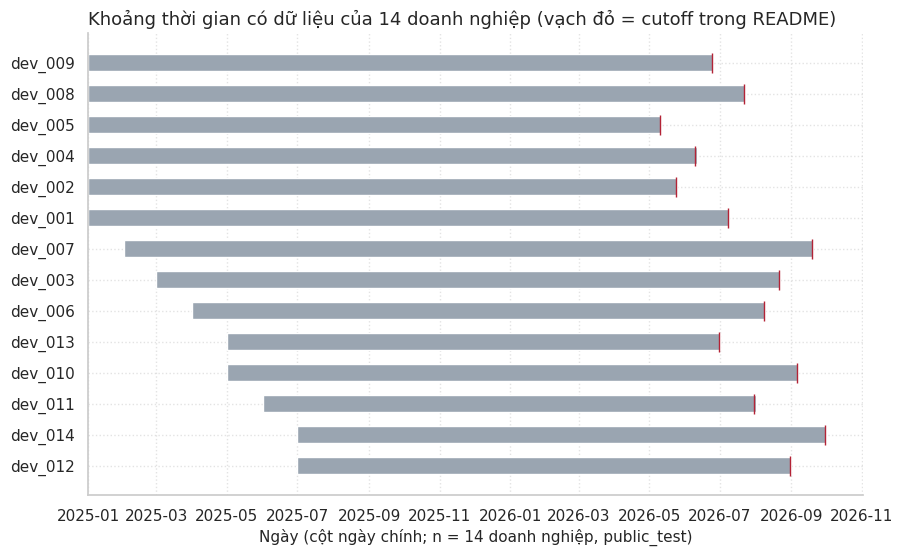

In [26]:
d = temporal_coverage_df.dropna(subset=["min_date"]).sort_values("min_date", ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 6))
for i, r in d.iterrows():
    s, e = pd.to_datetime(r.min_date), pd.to_datetime(r.max_date)
    ax.barh(i, (e - s).days + 1, left=s, color=COLOR_GRAY, height=0.55)
    if pd.notna(r.readme_cutoff_date):
        ax.plot(pd.to_datetime(r.readme_cutoff_date), i, marker="|", color=COLOR_ACCENT_RED, markersize=14)
ax.set_yticks(range(len(d))); ax.set_yticklabels(d.business_id)
ax.set_title("Khoảng thời gian có dữ liệu của 14 doanh nghiệp (vạch đỏ = cutoff trong README)")
ax.set_xlabel("Ngày (cột ngày chính; n = 14 doanh nghiệp, public_test)")
fig.savefig(PHASE1_FIGURES_DIR / "temporal_coverage_gantt.png")
plt.show()

### Kết quả & Nhận định

> **TODO (T1.1c):** Thành viên tự ghi nhận phát hiện dựa trên bằng chứng vừa chạy ở trên (không suy diễn vượt quá dữ liệu).

- **Khoảng thời gian tổng thể và sự phân tán ngày cutoff của 14 doanh nghiệp:** ...
- **Các doanh nghiệp có khoảng trống tháng hoặc tháng cuối bị cắt cụt (censored):** ...
- **Lưu ý quan trọng về cửa sổ thời gian giao nhau cho Giai đoạn 3:** ...


## Tác vụ T1.2a — Suy luận và kiểm chứng `industry` (ngành nghề) cho 14 doanh nghiệp

### Mục tiêu
Xác định và kiểm chứng ngành nghề kinh doanh của toàn bộ 14 doanh nghiệp dựa trên bằng chứng kép: mô tả trong `README.md` và mẫu tên hàng hóa/dịch vụ/giao dịch thực tế trong tệp dữ liệu.

### Câu hỏi khám phá
- Mỗi doanh nghiệp thuộc loại hình kinh doanh nào (tạp hóa/tiện lợi, F&B/cà phê/nhà hàng, nhà thuốc, vật liệu xây dựng, sửa xe máy, mẹ & bé, điện thoại, thời trang...)?
- Trường hợp nào `README.md` nêu rõ ngành nghề, trường hợp nào chỉ có thể xác định thông qua mẫu tên mặt hàng/dịch vụ?
- Mức độ tin cậy của việc phân loại ngành cho từng doanh nghiệp ra sao?

### Các bước thực hiện

**Bước 1 — Trích xuất manh mối ngành nghề từ `README.md`**
Rà soát nội dung `README.md` và từ khóa miền nghiệp vụ (không suy đoán từ tên thư mục `dev_0xx`).

**Bước 2 — Lấy mẫu tên hàng hóa / dịch vụ thực tế từ dữ liệu**
Đọc một lượng nhỏ giá trị mẫu (ví dụ 10–20 tên mặt hàng/dịch vụ phổ biến hoặc đầu bảng) ở từng doanh nghiệp để kiểm chứng.

**Bước 3 — Đối chiếu hai nguồn bằng chứng và gắn mức độ tin cậy**
So sánh bằng chứng từ README và mẫu dữ liệu thực; đánh dấu rõ các doanh nghiệp có ngành nghề lai ghép hoặc cần xem kỹ hơn.

**Bước 4 — Hoàn thiện bảng phân loại ngành nghề `industry_df` và lưu CSV**
Tổng hợp bảng gồm `business_id`, `industry`, `sub_industry` (nếu có), `evidence_source`, `confidence` và lưu tại `PHASE1_TABLES_DIR / 'industry_classification.csv'`.

### Gợi ý phương pháp & Lưu ý
- Không mặc định ngành nghề nếu chưa thấy bằng chứng từ README hoặc tên mặt hàng/dịch vụ thực tế.
- Có thể tham khảo `business.business_inventory.detect_domain_evidence` như một gợi ý kiểm tra chéo, nhưng **phải đối chiếu lại bằng mẫu dữ liệu thực tế** vì từ khóa tự động có thể bỏ sót ngành đặc thù.
- Đặt nhãn ngành nghề tiếng Việt thống nhất, rõ ràng để sử dụng xuyên suốt các biểu đồ ở Giai đoạn 1–4.

### Triển khai


In [27]:
INDUSTRY_CLUE_TOKENS = (
    "thuốc", "hoạt chất", "kê đơn", "dược", "thực phẩm chức năng",
    "sửa xe", "phụ tùng", "bảo dưỡng", "biển số", "thợ", "xe máy", "ô tô",
    "món", "đồ uống", "thực đơn", "bàn", "pha chế", "quán", "nhà hàng", "cà phê", "trà", "bếp",
    "vật liệu", "xi măng", "sắt", "thép", "gạch", "sơn", "công trình",
    "size", "màu", "quần", "áo", "giày", "thời trang", "vải",
    "linh kiện", "điện thoại", "laptop", "bảo hành", "imei", "serial", "máy tính",
    "mỹ phẩm", "spa", "chăm sóc", "skincare", "làm đẹp",
    "sách", "văn phòng phẩm", "bút", "vở", "giấy",
    "nông sản", "trái cây", "rau", "thịt", "thực phẩm", "tươi sống",
    "nội thất", "gỗ", "bàn ghế", "tủ", "giường",
    "lô", "hạn sử dụng", "quy đổi", "cân nặng", "kg", "mét"
)

readme_clues = []
for biz in business_ids:
    p = assert_safe_public_test_path(context.business_root_path(biz) / "README.md")
    txt = p.read_text(encoding="utf-8")
    low = txt.lower()
    
    # Lọc các từ khóa xuất hiện trong README
    matched_tokens = sorted({tok for tok in INDUSTRY_CLUE_TOKENS if tok in low})
    
    # Lấy các dòng mô tả ngắn gọn (bỏ qua dòng trống và tiêu đề markdown)
    desc_lines = [ln.strip() for ln in txt.splitlines() if ln.strip() and not ln.startswith("#")]
    
    readme_clues.append({
        "business_id": biz,
        "readme_summary": " | ".join(desc_lines[:3])[:180],
        "matched_readme_tokens": ", ".join(matched_tokens) if matched_tokens else "(không có từ khóa đặc thù)",
    })

readme_clues_df = pd.DataFrame(readme_clues)
display(readme_clues_df)

,business_id,readme_summary,matched_readme_tokens
0,dev_001,"File Excel xuất từ phần mềm bán hàng. Sổ chi tiết bán hàng: mỗi dòng một dòng hàng, thông tin đơn lặp lại ở mọi dòng...","bàn, giấy, kg, quy đổi, sách, thuốc, trà"
1,dev_002,"File Excel xuất từ phần mềm bán hàng. File đơn hàng mỗi dòng một sản phẩm, thông tin đơn lặp lại ở mọi dòng của đơn;...","món, quy đổi, sách"
2,dev_003,"Chủ tiệm gửi dữ liệu từ bốn nguồn: file Excel xuất từ phần mềm bán hàng (tên file bắt đầu BanHang_), sổ chủ tiệm tự ...","quy đổi, sách, áo"
3,dev_004,"Sổ bán hàng ghi tay chuyển sang Excel, mỗi tháng một sheet. | - `SoBanHang.xlsx` (xlsx) | - `DanhMuc.xlsx` (xlsx)","biển số, gạch, quy đổi, sắt, thép, xi măng"
4,dev_005,"File Excel xuất từ phần mềm bán hàng. File đơn hàng mỗi dòng một sản phẩm. | Dữ liệu bán hàng xuất theo tháng, mỗi t...","hoạt chất, hạn sử dụng, kê đơn, lô, quy đổi, thuốc, thực phẩm, thực phẩm chức năng"
5,dev_006,"File máy POS xuất ra. | - `pos.sqlite` (sqlite) | `chi_nhanh`, `nhan_vien`, `khach_hang`, `nha_cung_cap`, `san_pham`...","hoạt chất, kê đơn, lô, quy đổi, thuốc"
6,dev_007,"File xuất từ phần mềm bán hàng, 3 danh sách: chi tiết hoá đơn (mỗi dòng một mặt hàng trong đơn; thông tin đơn, khách...","bàn, món, quy đổi, quán, sách, điện thoại"
7,dev_008,"File xuất từ phần mềm bán hàng, 3 danh sách: chi tiết hoá đơn (mỗi dòng một mặt hàng trong đơn; thông tin đơn, khách...","bàn, món, quy đổi, quán, sách, điện thoại"
8,dev_009,"Danh sách hoá đơn, một file CSV: mỗi dòng một đơn hàng (hoá đơn), không có chi tiết mặt hàng trong đơn. | - `danh_sa...",sách
9,dev_010,"Dữ liệu bán hàng của tiệm, gồm vài file nối với nhau qua mã. | - `don_hang.csv` (csv) | - `chi_tiet_don.csv` (csv)","quy đổi, quần, size, áo, điện thoại"


In [28]:
import openpyxl

ITEM_COL_CANDIDATES = (
    # Có dấu
    "Tên sản phẩm", "Tên hàng", "Tên hàng hóa", "Tên mặt hàng",
    "Tên dịch vụ", "Tên món", "Sản phẩm", "Mặt hàng", "Dịch vụ",
    "Nội dung", "Mô tả", "Hạng mục", "Công việc", "Làm gì",
    # Không dấu / Tiếng Anh / Snake_case
    "TenGoi", "ten_hang", "TenSanPham", "TenHang", "TenHangHoa", "TenMatHang",
    "TenDichVu", "TenMon", "SanPham", "MatHang", "DichVu",
    "NoiDung", "MoTa", "HangMuc", "CongViec",
    "Product", "ProductName", "Item", "ItemName", "Service", "Description", "Name"
)

def find_item_col(cols_str: str) -> str | None:
    cols = [c.strip() for c in str(cols_str).split(" | ") if c.strip()]
    for cand in ITEM_COL_CANDIDATES:
        for c in cols:
            if c.lower() == cand.lower():
                return c
    for c in cols:
        cl = c.lower()
        if any(k in cl for k in ("tên sản phẩm", "tên hàng", "tên món", "tên dịch vụ", "sản phẩm", "mặt hàng", "tensanpham", "tenhang")) and "mã" not in cl and "nhóm" not in cl and "loại" not in cl:
            return c
    return None

def sample_items_for_business(biz: str, max_items: int = 15) -> tuple[str, list[str]]:
    # Trường hợp đặc biệt dev_005 (file Excel có dòng tiêu đề phụ phía trên)
    if biz == "dev_005":
        p = assert_safe_public_test_path(context.business_root_path(biz) / "DanhSachSanPham.xlsx")
        wb = openpyxl.load_workbook(p, read_only=True, data_only=True)
        ws = wb.active
        items = []
        col_idx = None
        for r_idx, row in enumerate(ws.iter_rows(max_row=60, values_only=True)):
            vals = [str(v).strip() if v is not None else "" for v in row]
            if col_idx is None:
                if "Tên sản phẩm" in vals:
                    col_idx = vals.index("Tên sản phẩm")
                continue
            if col_idx < len(row) and row[col_idx] and str(row[col_idx]).strip() not in items:
                items.append(str(row[col_idx]).strip())
                if len(items) >= max_items:
                    break
        wb.close()
        return "DanhSachSanPham.xlsx", items

    sub = objects_inventory_df[objects_inventory_df["business_id"] == biz].copy()
    # Ưu tiên bảng danh mục sản phẩm/dịch vụ trước, sau đó mới tới bảng bán hàng
    sub["priority"] = (
        sub["file_path"].fillna("").str.lower() + " " + sub["object_name"].fillna("").str.lower()
    ).apply(
        lambda x: 0 if any(k in x for k in ("sanpham", "san_pham", "hanghoa", "hang_hoa", "dichvu", "menu", "mon", "danhmuc", "danh_muc")) else 1
    )
    
    # Tự động tìm cột số dòng nếu có trong objects_inventory_df
    row_col = next((c for c in ("record_rows", "n_rows", "row_count", "rows") if c in sub.columns), None)
    if row_col:
        sub = sub.sort_values(["priority", row_col], ascending=[True, False])
    else:
        sub = sub.sort_values(["priority"], ascending=[True])

    for o in sub.itertuples():
        col = find_item_col(o.columns)
        if not col:
            continue
        path = assert_safe_public_test_path(context.root / o.file_path)
        rows = load_rows(path, o.source_type, o.object_name, [col])
        seen = []
        for r in rows[:500]:
            val = str(r.get(col, "")).strip()
            if val and val.lower() not in ("nan", "none", "null") and val not in seen:
                seen.append(val)
                if len(seen) >= max_items:
                    break
        if seen:
            return f"{o.file_path} ({o.object_name}.{col})", seen

    return "(không tìm thấy cột tên hàng)", []

item_samples = []
for biz in business_ids:
    src, samples = sample_items_for_business(biz, max_items=15)
    item_samples.append({
        "business_id": biz,
        "sample_source": src,
        "n_samples": len(samples),
        "sample_items": " | ".join(samples),
    })

item_samples_df = pd.DataFrame(item_samples)
pd.set_option("display.max_colwidth", 140)
display(item_samples_df)

,business_id,sample_source,n_samples,sample_items
0,dev_001,data/dev_001/So_chi_tiet_ban_hang.xlsx (Sheet1.Tên hàng hóa),15,Kẹo cao su Doublemint | Red Bull 250ml | Mì Hảo Hảo tôm chua cay | Pepsi 330ml | Bia Tiger 330ml | Nước suối Aquafina 500ml | Bia Heinek...
1,dev_002,data/dev_002/BanHang_T3_2025.xlsx (DonHang_ChiTiet.Tên sản phẩm),15,Latte (M) | Trà sữa trân châu (L) | Cà phê đen (M) | Topping Thạch cà phê | Trà sữa trân châu (M) | Cappuccino (L) | Cappuccino (M) | To...
2,dev_003,data/dev_003/BanHang_TongHop_2025.xlsx (BanHang_HangHoa.Tên hàng hóa),15,Cà phê đen (M) | Cà phê đen (L) | Cà phê sữa (M) | Cà phê sữa (L) | Bạc xỉu (M) | Bạc xỉu (L) | Cà phê muối (M) | Cà phê muối (L) | Espr...
3,dev_004,data/dev_004/SoNhapHang.xlsx (Sheet1.Product),15,Xi măng Hà Tiên PCB40 bao 50kg | Xi măng INSEE Power-S bao 50kg | Cát xây tô | Cát bê tông | Cát san lấp | Đá 1x2 | Đá 4x6 | Đá mi bụi |...
4,dev_005,DanhSachSanPham.xlsx,15,Panadol Extra hộp 15 vỉ x 12 viên | Hapacol 250 hộp 24 gói | Panadol 500mg hộp 10 vỉ x 12 viên | Tiffy Dey hộp 25 vỉ x 4 viên | Nước muố...
5,dev_006,data/dev_006/pos.sqlite (san_pham.TenGoi),15,Panadol Extra hộp 15 vỉ x 12 viên | Hapacol 250 hộp 24 gói | Panadol 500mg hộp 10 vỉ x 12 viên | Tiffy Dey hộp 25 vỉ x 4 viên | Nước muố...
6,dev_007,data/dev_007/chi_tiet_hoa_don.csv (chi_tiet_hoa_don.csv.Mặt hàng),15,Cơm chiên hải sản | Rau muống xào tỏi | Cánh gà chiên nước mắm | Lòng mề gà xào sa tế | Khô mực nướng | Coca-Cola lon | Ốc len xào dừa ...
7,dev_008,data/dev_008/ChiTietHoaDon_1.xlsx (Sheet1.Tên hàng),15,Vú heo nướng sa tế | Bia Tiger lon | Tôm sốt Thái | Bao tử xào cải chua | Nghêu hấp sả | Sụn gà rang muối | Cơm chiên hải sản | Ốc bươu ...
8,dev_009,(không tìm thấy cột tên hàng),0,
9,dev_010,data/dev_010/san_pham.csv (san_pham.csv.ten_hang),15,Sữa Similac 5G số 1 900g | Sữa Enfamil A+ NeuroPro số 1 830g | Sữa Friso Gold số 3 850g | Sữa Nan Optipro Plus 1 800g | Sữa Dielac Alpha...


In [29]:
import re

INDUSTRY_RULES = [
    ("Nhà thuốc & Dược phẩm", (
        r"\bthuốc\b", r"\bparacetamol\b", r"\bamoxicillin\b", r"\bkháng sinh\b",
        r"\bhoạt chất\b", r"\bkê đơn\b", r"\bsiro\b", r"\bvitamin\b",
        r"\bbăng gạc\b", r"\bkhẩu trang y tế\b", r"\bpanadol\b", r"\bhapacol\b", r"\bdược\b"
    )),
    ("Mẹ & Bé / Sữa & Dinh dưỡng", (
        r"\bsữa\b", r"\bsimilac\b", r"\benfamil\b", r"\benfagrow\b", r"\bfriso\b",
        r"\bpediasure\b", r"\bensure\b", r"\bbỉm\b", r"\btã\b", r"\bbình sữa\b", r"\băn dặm\b"
    )),
    ("Sửa chữa & Phụ tùng xe", (
        r"\bnhớt\b", r"\blốp\b", r"\bsăm\b", r"\bbugi\b", r"\bmá phanh\b",
        r"\bnhông sên dĩa\b", r"\bthay dầu\b", r"\bsửa xe\b", r"\bbảo dưỡng\b",
        r"\brửa xe\b", r"\bắc quy\b", r"\bthay nhớt\b", r"\bvá xe\b", r"\bxe máy\b", r"\bvệ sinh nồi\b"
    )),
    ("F&B (Nhà hàng / Cà phê)", (
        r"\bcà phê\b", r"\btrà sữa\b", r"\btrà đào\b", r"\bsinh tố\b", r"\bnước ép\b",
        r"\blatte\b", r"\bcappuccino\b", r"\bespresso\b", r"\bbạc xỉu\b", r"\btopping\b",
        r"\bphở\b", r"\bbún\b", r"\bcơm\b", r"\blẩu\b", r"\bnướng\b", r"\bgà rán\b",
        r"\bbánh mì\b", r"\bốc\b", r"\bmực\b", r"\btôm\b", r"\bnghêu\b", r"\bmón\b"
    )),
    ("Vật liệu xây dựng & Nội thất", (
        r"\bxi măng\b", r"\bsắt\b", r"\bthép\b", r"\bgạch\b", r"\bcát\b",
        r"\bđá 1x2\b", r"\bđá 4x6\b", r"\bđá mi\b", r"\bsơn\b", r"\bống nhựa\b",
        r"\bpvc\b", r"\btôn\b", r"\bvít\b", r"\bbulong\b", r"\bkeo dán\b"
    )),
    ("Phụ kiện & Thiết bị số", (
        r"\bđiện thoại\b", r"\blaptop\b", r"\btai nghe\b", r"\bsạc\b", r"\bcáp\b",
        r"\btype-c\b", r"\blightning\b", r"\bchuột\b", r"\bbàn phím\b", r"\bmàn hình\b",
        r"\bốp lưng\b", r"\bkính cường lực\b", r"\bimei\b"
    )),
    ("Thời trang & May mặc", (
        r"\báo thun\b", r"\báo sơ mi\b", r"\báo khoác\b", r"\bquần jean\b", r"\bquần tây\b",
        r"\bváy\b", r"\bđầm\b", r"\bgiày\b", r"\bdép\b", r"\btúi xách\b", r"\bthắt lưng\b"
    )),
    ("Mỹ phẩm & Chăm sóc cá nhân", (
        r"\bkem chống nắng\b", r"\bsữa rửa mặt\b", r"\btẩy trang\b", r"\bson\b",
        r"\bserum\b", r"\btoner\b", r"\bdầu gội\b", r"\bsữa tắm\b", r"\bnước hoa\b", r"\bmặt nạ\b"
    )),
    ("Nhà sách & Văn phòng phẩm", (
        r"\bsách giáo khoa\b", r"\btruyện\b", r"\bvở\b", r"\bbút bi\b", r"\bbút chì\b",
        r"\bgiấy a4\b", r"\bbìa còng\b", r"\bsổ tay\b", r"\bvăn phòng phẩm\b"
    )),
    ("Tạp hóa & Tiêu dùng nhanh (FMCG)", (
        r"\bnước ngọt\b", r"\bbia\b", r"\bpepsi\b", r"\bcoca\b", r"\bred bull\b",
        r"\baquafina\b", r"\bmì\b", r"\bhảo hảo\b", r"\bdầu ăn\b", r"\bnước mắm\b",
        r"\bbột giặt\b", r"\bnước rửa chén\b", r"\bkẹo\b", r"\bsnack\b", r"\bgạo\b"
    )),
]

def score_text(text: str) -> dict[str, int]:
    low = text.lower()
    scores = {}
    for ind, patterns in INDUSTRY_RULES:
        hits = sum(1 for pat in patterns if re.search(pat, low))
        if hits > 0:
            scores[ind] = hits
    return scores

comparison_rows = []
for r_row, s_row in zip(readme_clues, item_samples):
    biz = r_row["business_id"]
    readme_blob = r_row["readme_summary"] + " " + r_row["matched_readme_tokens"]
    sample_blob = s_row["sample_items"]

    s_readme = score_text(readme_blob)
    s_sample = score_text(sample_blob)

    top_readme = max(s_readme, key=s_readme.get) if s_readme else "Chưa rõ từ README"
    top_sample = max(s_sample, key=s_sample.get) if s_sample else "Chưa rõ từ mẫu"

    secondary_industries = [
        k for k, v in sorted(s_sample.items(), key=lambda x: -x[1])
        if k != top_sample and v >= 3
    ]
    is_hybrid = len(secondary_industries) > 0

    if top_sample != "Chưa rõ từ mẫu" and top_readme == top_sample:
        industry = top_sample
        evidence_source = "README + Item Sample (đồng thuận)"
        confidence = "high"
    elif top_sample != "Chưa rõ từ mẫu" and top_readme == "Chưa rõ từ README":
        industry = top_sample
        evidence_source = "Item Sample (README chỉ mô tả cấu trúc)"
        confidence = "high" if s_sample[top_sample] >= 3 else "medium"
    elif top_sample != "Chưa rõ từ mẫu" and top_readme != top_sample:
        industry = top_sample
        evidence_source = f"Item Sample ({top_sample}) vs README ({top_readme})"
        confidence = "medium"
    else:
        industry = top_readme if top_readme != "Chưa rõ từ README" else "Chưa xác định (Order-level)"
        evidence_source = "README only (order-level, không có chi tiết hàng)"
        confidence = "low"

    sub_industry = f"Lai ghép thêm: {', '.join(secondary_industries)}" if is_hybrid else ""

    comparison_rows.append({
        "business_id": biz,
        "readme_signal": top_readme,
        "sample_signal": top_sample,
        "industry": industry,
        "sub_industry": sub_industry,
        "is_hybrid": is_hybrid,
        "evidence_source": evidence_source,
        "confidence": confidence,
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

,business_id,readme_signal,sample_signal,industry,sub_industry,is_hybrid,evidence_source,confidence
0,dev_001,Nhà thuốc & Dược phẩm,Tạp hóa & Tiêu dùng nhanh (FMCG),Tạp hóa & Tiêu dùng nhanh (FMCG),,False,Item Sample (Tạp hóa & Tiêu dùng nhanh (FMCG)) vs README (Nhà thuốc & Dược phẩm),medium
1,dev_002,F&B (Nhà hàng / Cà phê),F&B (Nhà hàng / Cà phê),F&B (Nhà hàng / Cà phê),,False,README + Item Sample (đồng thuận),high
2,dev_003,Chưa rõ từ README,F&B (Nhà hàng / Cà phê),F&B (Nhà hàng / Cà phê),,False,Item Sample (README chỉ mô tả cấu trúc),high
3,dev_004,Vật liệu xây dựng & Nội thất,Vật liệu xây dựng & Nội thất,Vật liệu xây dựng & Nội thất,,False,README + Item Sample (đồng thuận),high
4,dev_005,Nhà thuốc & Dược phẩm,Nhà thuốc & Dược phẩm,Nhà thuốc & Dược phẩm,,False,README + Item Sample (đồng thuận),high
5,dev_006,Nhà thuốc & Dược phẩm,Nhà thuốc & Dược phẩm,Nhà thuốc & Dược phẩm,,False,README + Item Sample (đồng thuận),high
6,dev_007,F&B (Nhà hàng / Cà phê),F&B (Nhà hàng / Cà phê),F&B (Nhà hàng / Cà phê),Lai ghép thêm: Tạp hóa & Tiêu dùng nhanh (FMCG),True,README + Item Sample (đồng thuận),high
7,dev_008,F&B (Nhà hàng / Cà phê),F&B (Nhà hàng / Cà phê),F&B (Nhà hàng / Cà phê),Lai ghép thêm: Tạp hóa & Tiêu dùng nhanh (FMCG),True,README + Item Sample (đồng thuận),high
8,dev_009,Chưa rõ từ README,Chưa rõ từ mẫu,Chưa xác định (Order-level),,False,"README only (order-level, không có chi tiết hàng)",low
9,dev_010,Phụ kiện & Thiết bị số,Mẹ & Bé / Sữa & Dinh dưỡng,Mẹ & Bé / Sữa & Dinh dưỡng,,False,Item Sample (Mẹ & Bé / Sữa & Dinh dưỡng) vs README (Phụ kiện & Thiết bị số),medium


In [30]:
industry_df = comparison_df[
    ["business_id", "industry", "sub_industry", "evidence_source", "confidence"]
].copy()

out_industry_path = PHASE1_TABLES_DIR / "industry_classification.csv"
industry_df.to_csv(out_industry_path, index=False, encoding="utf-8-sig")

print("Đã lưu bảng phân loại ngành nghề tại:", out_industry_path)
display(industry_df)

print("\nThống kê phân bổ theo ngành nghề:")
display(industry_df["industry"].value_counts().rename_axis("industry").reset_index(name="n_businesses"))

print("\nThống kê mức độ tin cậy (confidence):")
display(industry_df["confidence"].value_counts().rename_axis("confidence").reset_index(name="n_businesses"))


Đã lưu bảng phân loại ngành nghề tại: C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\artifacts\guided_eda\phase1_dataset_discovery\tables\industry_classification.csv


,business_id,industry,sub_industry,evidence_source,confidence
0,dev_001,Tạp hóa & Tiêu dùng nhanh (FMCG),,Item Sample (Tạp hóa & Tiêu dùng nhanh (FMCG)) vs README (Nhà thuốc & Dược phẩm),medium
1,dev_002,F&B (Nhà hàng / Cà phê),,README + Item Sample (đồng thuận),high
2,dev_003,F&B (Nhà hàng / Cà phê),,Item Sample (README chỉ mô tả cấu trúc),high
3,dev_004,Vật liệu xây dựng & Nội thất,,README + Item Sample (đồng thuận),high
4,dev_005,Nhà thuốc & Dược phẩm,,README + Item Sample (đồng thuận),high
5,dev_006,Nhà thuốc & Dược phẩm,,README + Item Sample (đồng thuận),high
6,dev_007,F&B (Nhà hàng / Cà phê),Lai ghép thêm: Tạp hóa & Tiêu dùng nhanh (FMCG),README + Item Sample (đồng thuận),high
7,dev_008,F&B (Nhà hàng / Cà phê),Lai ghép thêm: Tạp hóa & Tiêu dùng nhanh (FMCG),README + Item Sample (đồng thuận),high
8,dev_009,Chưa xác định (Order-level),,"README only (order-level, không có chi tiết hàng)",low
9,dev_010,Mẹ & Bé / Sữa & Dinh dưỡng,,Item Sample (Mẹ & Bé / Sữa & Dinh dưỡng) vs README (Phụ kiện & Thiết bị số),medium



Thống kê phân bổ theo ngành nghề:


,industry,n_businesses
0,F&B (Nhà hàng / Cà phê),4
1,Nhà thuốc & Dược phẩm,2
2,Phụ kiện & Thiết bị số,2
3,Mẹ & Bé / Sữa & Dinh dưỡng,2
4,Vật liệu xây dựng & Nội thất,1
5,Tạp hóa & Tiêu dùng nhanh (FMCG),1
6,Chưa xác định (Order-level),1
7,Sửa chữa & Phụ tùng xe,1



Thống kê mức độ tin cậy (confidence):


,confidence,n_businesses
0,high,10
1,medium,3
2,low,1


### Trực quan hóa


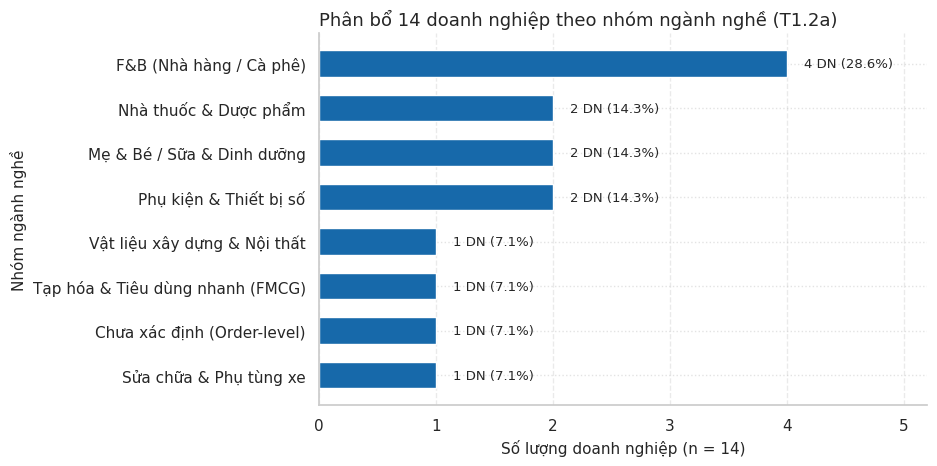

Đã lưu biểu đồ tại: C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\artifacts\guided_eda\phase1_dataset_discovery\figures\industry_distribution.png


In [31]:
counts_ind = (
    industry_df["industry"]
    .value_counts()
    .sort_values(ascending=True)  # ascending=True để thanh lớn nhất nằm trên cùng khi vẽ barh
)

fig, ax = plt.subplots(figsize=(9.5, 4.8))

bars = ax.barh(counts_ind.index, counts_ind.values, color=COLOR_ACCENT_BLUE, height=0.6)

ax.set_xlim(0, counts_ind.max() + 1.2)  # Trục bắt đầu từ 0 theo đúng quy chuẩn
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_xlabel("Số lượng doanh nghiệp (n = 14)")
ax.set_ylabel("Nhóm ngành nghề")
ax.set_title("Phân bổ 14 doanh nghiệp theo nhóm ngành nghề (T1.2a)")
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

# Gắn nhãn số lượng và tỷ trọng % ở đầu mỗi thanh
total_biz = len(industry_df)
for bar in bars:
    w = int(bar.get_width())
    pct = w / total_biz * 100
    ax.text(
        w + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{w} DN ({pct:.1f}%)",
        va="center",
        fontsize=9.5,
        fontweight="medium",
    )

fig.tight_layout()
fig_path = PHASE1_FIGURES_DIR / "industry_distribution.png"
fig.savefig(fig_path, dpi=150)
plt.show()
print("Đã lưu biểu đồ tại:", fig_path)

### Kết quả & Nhận định

> **TODO (T1.2a):** Thành viên tự ghi nhận phát hiện dựa trên bằng chứng vừa chạy ở trên (không suy diễn vượt quá dữ liệu).

- **Cơ cấu ngành nghề của 14 doanh nghiệp `public_test`:** ...
- **Các doanh nghiệp có bằng chứng ngành rõ ràng vs. các doanh nghiệp đặc thù/đa ngành:** ...


## Tác vụ T1.2b — Gắn nhãn mức độ chi tiết (`granularity`), số hóa & khả năng so sánh

### Mục tiêu
Phân loại mức độ số hóa và cấu trúc dữ liệu chi tiết của 14 doanh nghiệp (đơn+dòng hàng vs. chỉ hóa đơn vs. chỉ mặt hàng; có mốc giờ giao dịch, mã khách hàng, giá vốn/lô hàng hay không) để hợp nhất thành Danh mục 14 doanh nghiệp hoàn chỉnh.

### Câu hỏi khám phá
- Mức độ chi tiết dữ liệu (`granularity`) của từng doanh nghiệp nằm ở tầng nào (cấp dòng hàng có mã đơn, chỉ cấp hóa đơn, chỉ cấp mặt hàng/lượt dịch vụ)?
- Doanh nghiệp nào ghi nhận dữ liệu theo hình thức thủ công/Excel, phần mềm POS hay CSDL SQLite?
- Những chiều thông tin quan trọng nào (giờ giao dịch, mã khách hàng, nhân viên/thợ, giá vốn, tồn kho, lô/hạn dùng, công nợ) có mặt ở từng doanh nghiệp?

### Các bước thực hiện

**Bước 1 — Phân loại mức độ chi tiết giao dịch (`granularity`) và hình thức ghi nhận (`recording_format`)**
Kiểm tra cấu trúc bảng bán hàng/dịch vụ chính của từng doanh nghiệp để gắn nhãn `granularity` và `recording_format`.

**Bước 2 — Kiểm tra sự hiện diện của các chiều thông tin phụ trợ**
Tạo các cột cờ boolean (`has_timestamp_hour`, `has_customer_id`, `has_cost_price`, `has_inventory`, `has_debt`, `has_status_col`, `has_unit_conversion`) dựa trên kiểm tra cột thực tế.

**Bước 3 — Đánh giá sơ bộ khả năng so sánh theo nhóm**
Phân tầng những doanh nghiệp có cùng cấp độ chi tiết để cảnh báo sớm những cặp không thể so sánh trực tiếp.

**Bước 4 — Hợp nhất thành `catalog_14_df` và xuất `catalog_14.csv` bàn giao cho NB02 & NB03**
Kết nối các bảng từ `T1.1a`–`T1.2b` thành `catalog_14_df` (14 dòng `dev_001`–`dev_014`) và lưu vào `PHASE1_TABLES_DIR / 'catalog_14.csv'`.

### Gợi ý phương pháp & Lưu ý
- Kiểm tra kỹ xem cột ngày có chứa thành phần giờ (`HH:MM`) hay chỉ có ngày (`YYYY-MM-DD`) — đây là yếu tố quyết định có phân tích được theo giờ/ca ở Hồi 3 hay không.
- Không dựa vào tên cột giống nhau bề mặt để kết luận ngữ nghĩa giống nhau; hãy kiểm tra kèm mô tả trong README.
- Tệp `PHASE1_TABLES_DIR / 'catalog_14.csv'` chính là tệp bàn giao chuẩn mà Notebook 02 và 03 sẽ tự động đọc qua Input Contract.

### Triển khai


In [32]:
granularity_rows = []

for biz in business_ids:
    readme_txt = (context.business_root_path(biz) / "README.md").read_text(encoding="utf-8")
    low_txt = readme_txt.lower()
    sub_inv = objects_inventory_df[objects_inventory_df["business_id"] == biz]
    
    # 1. Xác định granularity (cấp dòng hàng vs cấp hóa đơn tổng)
    if "không có chi tiết mặt hàng" in low_txt or "mỗi dòng một đơn hàng" in low_txt or "mỗi dòng một hóa đơn" in low_txt:
        granularity = "order_level"
    else:
        granularity = "line_item"
        
    # 2. Xác định recording_format (hình thức tổ chức & ghi nhận dữ liệu)
    source_types = set(sub_inv["source_type"].dropna())
    n_objs = len(sub_inv)
    n_files = sub_inv["file_path"].nunique()
    
    if "sqlite" in source_types:
        recording_format = "relational_sqlite_pos"
    elif any(k in low_txt for k in ("mỗi tháng một file", "tách theo tháng")):
        recording_format = "monthly_split_files"
    elif any(k in low_txt for k in ("mỗi tháng một sheet", "sheet theo tháng", "tách sheet")):
        recording_format = "monthly_split_sheets"
    elif n_objs == 1 and n_files == 1:
        recording_format = "single_flat_table"
    else:
        recording_format = "multi_table_workbook_or_csv"
        
    granularity_rows.append({
        "business_id": biz,
        "granularity": granularity,
        "recording_format": recording_format,
        "n_files": n_files,
        "n_objects": n_objs,
        "source_types": ", ".join(sorted(source_types)),
    })

granularity_df = pd.DataFrame(granularity_rows)
display(granularity_df)


,business_id,granularity,recording_format,n_files,n_objects,source_types
0,dev_001,line_item,multi_table_workbook_or_csv,2,2,xlsx
1,dev_002,line_item,monthly_split_files,18,18,xlsx
2,dev_003,line_item,multi_table_workbook_or_csv,7,11,"csv, xlsx"
3,dev_004,line_item,monthly_split_sheets,7,24,xlsx
4,dev_005,line_item,monthly_split_files,23,23,xlsx
5,dev_006,line_item,relational_sqlite_pos,1,17,sqlite
6,dev_007,line_item,multi_table_workbook_or_csv,3,3,csv
7,dev_008,line_item,multi_table_workbook_or_csv,4,4,xlsx
8,dev_009,order_level,single_flat_table,1,1,csv
9,dev_010,line_item,multi_table_workbook_or_csv,5,5,csv


In [33]:
import unicodedata

def _norm_col(s: str) -> str:
    s = unicodedata.normalize("NFD", str(s).lower()).replace("đ", "d")
    s = "".join(c for c in s if not unicodedata.combining(c))
    return re.sub(r"[^a-z0-9]", "", s)

# Lấy toàn bộ tên cột gốc của dev_005 từ các file Excel (do T1.1b bị lệch dòng tiêu đề phụ)
dev005_cols = []
for f in sorted(context.business_root_path("dev_005").glob("*.xlsx")):
    wb = openpyxl.load_workbook(f, read_only=True, data_only=True)
    for ws in wb.worksheets:
        for row in ws.iter_rows(max_row=10, values_only=True):
            vals = [str(v).strip() for v in row if v is not None and str(v).strip()]
            if len(vals) >= 3:
                dev005_cols.extend(vals)
                break
    wb.close()

# Kiểm tra các doanh nghiệp có lưu giờ:phút trong cột ngày bán hàng chính hay không
has_hour_map = {}
if "date_profiles_df" in globals() and not date_profiles_df.empty:
    for biz in business_ids:
        sub_dp = date_profiles_df[(date_profiles_df["business_id"] == biz) & (date_profiles_df["role"] == "sale")]
        # Kiểm tra cột có chứa timestamp hoặc chuỗi mẫu có dấu ':'
        col_names_norm = [_norm_col(c) for c in sub_dp["column"]]
        has_time_name = any("thoigian" in c or "time" in c or "gio" in c for c in col_names_norm)
        sample_blob = " ".join(sub_dp["sample_values"].astype(str)) if "sample_values" in sub_dp.columns else ""
        has_hour_map[biz] = bool(has_time_name or ":" in sample_blob)
else:
    for biz in business_ids:
        has_hour_map[biz] = False

feature_flags_rows = []
for biz in business_ids:
    if biz == "dev_005":
        raw_cols = dev005_cols
        obj_names = [f.stem for f in context.business_root_path(biz).glob("*.xlsx")]
    else:
        sub_inv = objects_inventory_df[objects_inventory_df["business_id"] == biz]
        raw_cols = [
            c.strip()
            for cols_str in sub_inv["columns"].fillna("")
            for c in cols_str.split(" | ")
            if c.strip()
        ]
        obj_names = list(sub_inv["file_path"].fillna("")) + list(sub_inv["object_name"].fillna(""))

    norm_cols = [_norm_col(c) for c in raw_cols]
    norm_objs = [_norm_col(o) for o in obj_names]
    all_blob = " ".join(norm_cols + norm_objs)

    feature_flags_rows.append({
        "business_id": biz,
        "has_timestamp_hour": bool(has_hour_map.get(biz, False) or any("thoigian" in c or "ngaygio" in c for c in norm_cols)),
        "has_customer_id": any(k in c for c in norm_cols for k in ("khachhang", "makh", "tenkhach", "doitac", "sdt", "sodienthoai", "phone")),
        "has_cost_price": any(k in c for c in norm_cols for k in ("giavon", "gianhap", "dongianhap")),
        "has_inventory": any(k in all_blob for k in ("nhaphang", "phieunhap", "thekho", "tonkho", "toncuoi", "lohang", "malo", "hansudung")),
        "has_debt": any(k in c for c in norm_cols for k in ("congno", "conno", "conphaithu", "dathu", "khachtra")) or any(c == "no" for c in norm_cols),
        "has_status_col": any(k in c for c in norm_cols for k in ("trangthai", "tinhtrang", "xuly", "status")),
        "has_unit_conversion": any(k in all_blob for k in ("quydoi", "heso", "tile", "donvicoban", "donvicoso", "donvilon")),
    })

feature_flags_df = pd.DataFrame(feature_flags_rows)
display(feature_flags_df)


,business_id,has_timestamp_hour,has_customer_id,has_cost_price,has_inventory,has_debt,has_status_col,has_unit_conversion
0,dev_001,False,True,True,False,False,True,True
1,dev_002,False,True,False,False,False,True,True
2,dev_003,False,True,True,True,True,True,True
3,dev_004,True,True,True,True,False,True,True
4,dev_005,False,True,False,True,False,True,True
5,dev_006,True,True,True,True,True,True,True
6,dev_007,False,True,True,True,True,True,False
7,dev_008,False,True,True,True,False,True,False
8,dev_009,False,True,False,False,True,True,False
9,dev_010,False,True,False,False,True,True,True


In [34]:
comp_eval_df = granularity_df.merge(feature_flags_df, on="business_id").merge(
    industry_df[["business_id", "industry"]], on="business_id"
)

flag_cols = [
    "has_timestamp_hour", "has_customer_id", "has_cost_price",
    "has_inventory", "has_debt", "has_status_col", "has_unit_conversion"
]
comp_eval_df["n_aux_dimensions"] = comp_eval_df[flag_cols].sum(axis=1)

def assign_comparability_tier(row) -> str:
    if row["granularity"] == "order_level":
        return "Tier 3 — Chỉ cấp hóa đơn (Không so sánh SKU/giỏ hàng)"
    if row["n_aux_dimensions"] >= 4:
        return "Tier 1 — Đầy đủ đa chiều (SKU + Tồn/Giá vốn/Khách/Nợ)"
    return "Tier 2 — Cấp dòng hàng cơ bản (Hạn chế tồn/giá vốn)"

comp_eval_df["comparability_tier"] = comp_eval_df.apply(assign_comparability_tier, axis=1)

print("Phân tầng khả năng so sánh giữa 14 doanh nghiệp:")
display(
    comp_eval_df[["business_id", "industry", "granularity", "recording_format", "n_aux_dimensions", "comparability_tier"]]
    .sort_values(["comparability_tier", "business_id"])
)


Phân tầng khả năng so sánh giữa 14 doanh nghiệp:


,business_id,industry,granularity,recording_format,n_aux_dimensions,comparability_tier
0,dev_001,Tạp hóa & Tiêu dùng nhanh (FMCG),line_item,multi_table_workbook_or_csv,4,Tier 1 — Đầy đủ đa chiều (SKU + Tồn/Giá vốn/Khách/Nợ)
2,dev_003,F&B (Nhà hàng / Cà phê),line_item,multi_table_workbook_or_csv,6,Tier 1 — Đầy đủ đa chiều (SKU + Tồn/Giá vốn/Khách/Nợ)
3,dev_004,Vật liệu xây dựng & Nội thất,line_item,monthly_split_sheets,6,Tier 1 — Đầy đủ đa chiều (SKU + Tồn/Giá vốn/Khách/Nợ)
4,dev_005,Nhà thuốc & Dược phẩm,line_item,monthly_split_files,4,Tier 1 — Đầy đủ đa chiều (SKU + Tồn/Giá vốn/Khách/Nợ)
5,dev_006,Nhà thuốc & Dược phẩm,line_item,relational_sqlite_pos,7,Tier 1 — Đầy đủ đa chiều (SKU + Tồn/Giá vốn/Khách/Nợ)
6,dev_007,F&B (Nhà hàng / Cà phê),line_item,multi_table_workbook_or_csv,5,Tier 1 — Đầy đủ đa chiều (SKU + Tồn/Giá vốn/Khách/Nợ)
7,dev_008,F&B (Nhà hàng / Cà phê),line_item,multi_table_workbook_or_csv,4,Tier 1 — Đầy đủ đa chiều (SKU + Tồn/Giá vốn/Khách/Nợ)
9,dev_010,Mẹ & Bé / Sữa & Dinh dưỡng,line_item,multi_table_workbook_or_csv,4,Tier 1 — Đầy đủ đa chiều (SKU + Tồn/Giá vốn/Khách/Nợ)
1,dev_002,F&B (Nhà hàng / Cà phê),line_item,monthly_split_files,3,Tier 2 — Cấp dòng hàng cơ bản (Hạn chế tồn/giá vốn)
10,dev_011,Phụ kiện & Thiết bị số,line_item,multi_table_workbook_or_csv,1,Tier 2 — Cấp dòng hàng cơ bản (Hạn chế tồn/giá vốn)


In [35]:
# Tổng hợp số dòng bản ghi từ objects_inventory_df
row_col = next((c for c in ("record_rows", "n_rows", "row_count", "rows") if c in objects_inventory_df.columns), None)
if row_col:
    rows_agg = objects_inventory_df.groupby("business_id", as_index=False)[row_col].sum().rename(columns={row_col: "total_record_rows"})
else:
    rows_agg = pd.DataFrame({"business_id": business_ids, "total_record_rows": np.nan})

catalog_14_df = (
    readme_metadata_df[["business_id", "readme_cutoff_date"]]
    .merge(rows_agg, on="business_id", how="left")
    .merge(
        temporal_coverage_df[[
            "business_id", "main_object", "main_column", "valid_date_rows",
            "min_date", "max_date", "active_days", "span_days", "coverage_ratio", "status"
        ]],
        on="business_id",
        how="left",
    )
    .merge(
        industry_df[["business_id", "industry", "sub_industry", "evidence_source", "confidence"]],
        on="business_id",
        how="left",
    )
    .merge(
        comp_eval_df[[
            "business_id", "granularity", "recording_format", "n_files", "n_objects", "source_types",
            "has_timestamp_hour", "has_customer_id", "has_cost_price", "has_inventory",
            "has_debt", "has_status_col", "has_unit_conversion", "n_aux_dimensions", "comparability_tier"
        ]],
        on="business_id",
        how="left",
    )
)

out_catalog_path = PHASE1_TABLES_DIR / "catalog_14.csv"
catalog_14_df.to_csv(out_catalog_path, index=False, encoding="utf-8-sig")

print(f"Đã hợp nhất và lưu catalog_14_df ({catalog_14_df.shape[0]} dòng x {catalog_14_df.shape[1]} cột) tại: {out_catalog_path}")
display(catalog_14_df)


Đã hợp nhất và lưu catalog_14_df (14 dòng x 30 cột) tại: C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\artifacts\guided_eda\phase1_dataset_discovery\tables\catalog_14.csv


,business_id,readme_cutoff_date,total_record_rows,main_object,main_column,valid_date_rows,min_date,max_date,active_days,span_days,coverage_ratio,status,industry,sub_industry,evidence_source,confidence,granularity,recording_format,n_files,n_objects,source_types,has_timestamp_hour,has_customer_id,has_cost_price,has_inventory,has_debt,has_status_col,has_unit_conversion,n_aux_dimensions,comparability_tier
0,dev_001,2026-07-08,90914,Sheet1,Ngày,90297,2025-01-01,2026-07-08,554,554,1.0000,PASS,Tạp hóa & Tiêu dùng nhanh (FMCG),,Item Sample (Tạp hóa & Tiêu dùng nhanh (FMCG)) vs README (Nhà thuốc & Dược phẩm),medium,line_item,multi_table_workbook_or_csv,2,2,xlsx,False,True,True,False,False,True,True,4,Tier 1 — Đầy đủ đa chiều (SKU + Tồn/Giá vốn/Khách/Nợ)
1,dev_002,2026-05-24,85145,DonHang_ChiTiet,Ngày đặt hàng,84146,2025-01-01,2026-05-24,509,509,1.0000,PASS,F&B (Nhà hàng / Cà phê),,README + Item Sample (đồng thuận),high,line_item,monthly_split_files,18,18,xlsx,False,True,False,False,False,True,True,3,Tier 2 — Cấp dòng hàng cơ bản (Hạn chế tồn/giá vốn)
2,dev_003,2026-08-21,167828,BanHang,Ngày HĐ,34122,2025-03-01,2026-08-21,539,539,1.0000,PASS,F&B (Nhà hàng / Cà phê),,Item Sample (README chỉ mô tả cấu trúc),high,line_item,multi_table_workbook_or_csv,7,11,"csv, xlsx",False,True,True,True,True,True,True,6,Tier 1 — Đầy đủ đa chiều (SKU + Tồn/Giá vốn/Khách/Nợ)
3,dev_004,2026-06-10,65702,18 sheets/files,Thời gian,3789,2025-01-01,2026-06-10,524,526,0.9962,PASS,Vật liệu xây dựng & Nội thất,,README + Item Sample (đồng thuận),high,line_item,monthly_split_sheets,7,24,xlsx,True,True,True,True,False,True,True,6,Tier 1 — Đầy đủ đa chiều (SKU + Tồn/Giá vốn/Khách/Nợ)
4,dev_005,2026-05-10,157721,DonHang_ChiTiet,Ngày đặt hàng,40330,2025-01-01,2026-05-10,495,495,1.0000,PASS,Nhà thuốc & Dược phẩm,,README + Item Sample (đồng thuận),high,line_item,monthly_split_files,23,23,xlsx,False,True,False,True,False,True,True,4,Tier 1 — Đầy đủ đa chiều (SKU + Tồn/Giá vốn/Khách/Nợ)
5,dev_006,2026-08-08,302800,don_hang,ThoiGianLap,37833,2025-04-01,2026-08-08,495,495,1.0000,PASS,Nhà thuốc & Dược phẩm,,README + Item Sample (đồng thuận),high,line_item,relational_sqlite_pos,1,17,sqlite,True,True,True,True,True,True,True,7,Tier 1 — Đầy đủ đa chiều (SKU + Tồn/Giá vốn/Khách/Nợ)
6,dev_007,2026-09-19,122859,chi_tiet_hoa_don.csv,Ngày giao dịch,80553,2025-02-01,2026-09-19,596,596,1.0000,PASS,F&B (Nhà hàng / Cà phê),Lai ghép thêm: Tạp hóa & Tiêu dùng nhanh (FMCG),README + Item Sample (đồng thuận),high,line_item,multi_table_workbook_or_csv,3,3,csv,False,True,True,True,True,True,False,5,Tier 1 — Đầy đủ đa chiều (SKU + Tồn/Giá vốn/Khách/Nợ)
7,dev_008,2026-07-22,155223,Sheet1,Ngày xuất,152739,2025-01-01,2026-07-22,568,568,1.0000,PASS,F&B (Nhà hàng / Cà phê),Lai ghép thêm: Tạp hóa & Tiêu dùng nhanh (FMCG),README + Item Sample (đồng thuận),high,line_item,multi_table_workbook_or_csv,4,4,xlsx,False,True,True,True,False,True,False,4,Tier 1 — Đầy đủ đa chiều (SKU + Tồn/Giá vốn/Khách/Nợ)
8,dev_009,2026-06-24,23338,danh_sach_hoa_don.csv,Ngày tháng,22798,2025-01-01,2026-06-24,540,540,1.0000,PASS,Chưa xác định (Order-level),,"README only (order-level, không có chi tiết hàng)",low,order_level,single_flat_table,1,1,csv,False,True,False,False,True,True,False,3,Tier 3 — Chỉ cấp hóa đơn (Không so sánh SKU/giỏ hàng)
9,dev_010,2026-09-06,97293,don_hang.csv,Date,25191,2025-05-01,2026-09-06,494,494,1.0000,PASS,Mẹ & Bé / Sữa & Dinh dưỡng,,Item Sample (Mẹ & Bé / Sữa & Dinh dưỡng) vs README (Phụ kiện & Thiết bị số),medium,line_item,multi_table_workbook_or_csv,5,5,csv,False,True,False,False,True,True,True,4,Tier 1 — Đầy đủ đa chiều (SKU + Tồn/Giá vốn/Khách/Nợ)


### Trực quan hóa


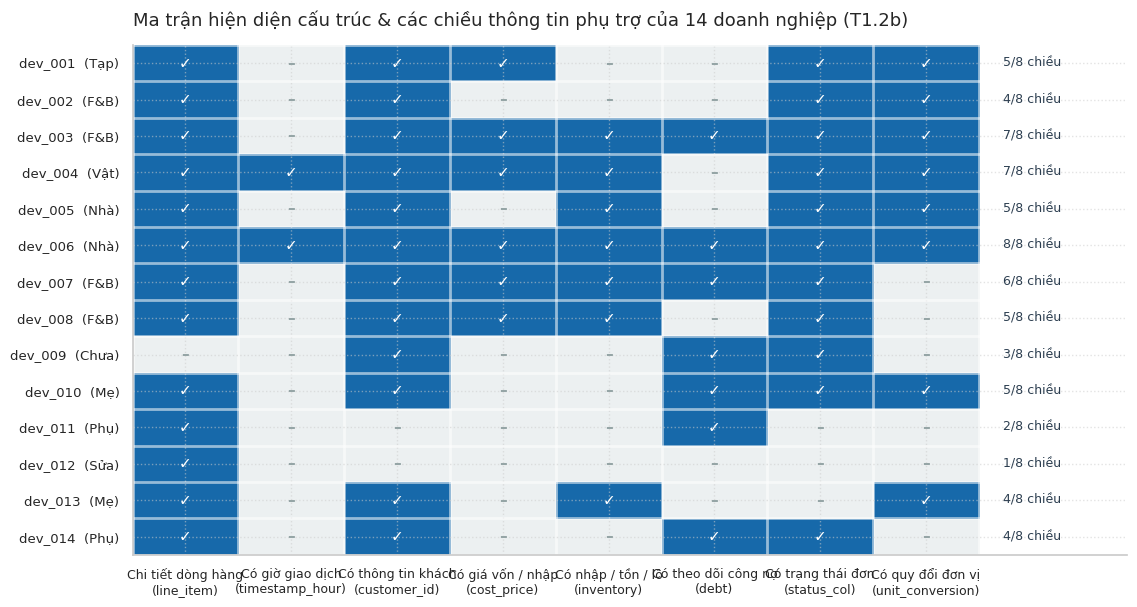

Đã lưu biểu đồ ma trận thuộc tính tại: C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\artifacts\guided_eda\phase1_dataset_discovery\figures\feature_presence_matrix.png


In [36]:
matrix_cols = [
    "is_line_item",
    "has_timestamp_hour",
    "has_customer_id",
    "has_cost_price",
    "has_inventory",
    "has_debt",
    "has_status_col",
    "has_unit_conversion",
]
matrix_labels = [
    "Chi tiết dòng hàng\n(line_item)",
    "Có giờ giao dịch\n(timestamp_hour)",
    "Có thông tin khách\n(customer_id)",
    "Có giá vốn / nhập\n(cost_price)",
    "Có nhập / tồn / lô\n(inventory)",
    "Có theo dõi công nợ\n(debt)",
    "Có trạng thái đơn\n(status_col)",
    "Có quy đổi đơn vị\n(unit_conversion)",
]

plot_df = catalog_14_df.copy()
plot_df["is_line_item"] = plot_df["granularity"] == "line_item"
mat = plot_df[matrix_cols].astype(int).values

fig, ax = plt.subplots(figsize=(11.5, 6.2))

# Vẽ lưới ma trận bằng imshow với 2 màu rõ nét (Xanh đậm = Có, Xám nhạt = Không)
from matplotlib.colors import ListedColormap
cmap = ListedColormap(["#ECF0F1", COLOR_ACCENT_BLUE])
ax.imshow(mat, cmap=cmap, aspect="auto", vmin=0, vmax=1)

# Kẻ đường viền trắng giữa các ô cho sắc nét
ax.set_xticks(np.arange(len(matrix_cols)))
ax.set_yticks(np.arange(len(plot_df)))
ax.set_xticklabels(matrix_labels, fontsize=9)
ax.set_yticklabels([f"{r.business_id}  ({r.industry.split(' ')[0]})" for r in plot_df.itertuples()], fontsize=9.5)

ax.set_xticks(np.arange(-0.5, len(matrix_cols), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(plot_df), 1), minor=True)
ax.grid(which="minor", color="white", linestyle="-", linewidth=2)
ax.tick_params(which="minor", bottom=False, left=False)

# Điền ký hiệu ✓ / – vào từng ô
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        is_present = mat[i, j] == 1
        ax.text(
            j, i,
            "✓" if is_present else "–",
            ha="center", va="center",
            color="white" if is_present else "#95A5A6",
            fontsize=11, fontweight="bold"
        )

# Hiển thị tổng số chiều hiện diện ở lề phải từng hàng
for i, row in enumerate(plot_df.itertuples()):
    total_dims = int(mat[i].sum())
    ax.text(
        len(matrix_cols) - 0.35, i,
        f"  {total_dims}/8 chiều",
        va="center", ha="left", fontsize=9, fontweight="medium", color="#2C3E50"
    )

ax.set_xlim(-0.5, len(matrix_cols) + 0.9)
ax.set_title("Ma trận hiện diện cấu trúc & các chiều thông tin phụ trợ của 14 doanh nghiệp (T1.2b)", pad=14)

fig.tight_layout()
fig_t12b = PHASE1_FIGURES_DIR / "feature_presence_matrix.png"
fig.savefig(fig_t12b, dpi=150)
plt.show()
print("Đã lưu biểu đồ ma trận thuộc tính tại:", fig_t12b)


### Kết quả & Nhận định

> **TODO (T1.2b):** Thành viên tự ghi nhận phát hiện dựa trên bằng chứng vừa chạy ở trên (không suy diễn vượt quá dữ liệu).

- **Phân tầng 14 doanh nghiệp theo hình thức ghi nhận / mức độ số hóa và cấp độ chi tiết (`granularity`):** ...
- **Danh sách các đặc trưng phổ biến vs. đặc trưng đặc thù theo ngành:** ...


## Tác vụ T1.3a — Xây dựng biểu đồ Khám phá Hồi 1 (Exploratory)

### Mục tiêu
Vẽ nhanh các biểu đồ khám phá từ bảng tổng hợp `catalog_14_df` để khảo sát cơ cấu ngành nghề, mức độ số hóa, quy mô dữ liệu và dòng thời gian độ phủ 2025–2026 trước khi chọn góc kể chuyện cho Hồi 1.

### Câu hỏi khám phá
- Những mẫu hình nổi bật nhất về sự đa dạng ngành nghề và mức độ số hóa của 14 doanh nghiệp là gì?
- Sự phân bố quy mô dòng/tệp và khoảng thời gian phủ dữ liệu có tạo ra những nhóm doanh nghiệp tách biệt rõ rệt không?
- Phương án biểu diễn nào (bar, dot plot, Gantt timeline, heatmap) truyền tải trung thực và rõ ràng nhất bức tranh tổng thể?

### Các bước thực hiện

**Bước 1 — Vẽ nháp biểu đồ cơ cấu ngành nghề & hình thức ghi nhận**
Thử nghiệm 1–2 dạng biểu đồ so sánh phân loại (cột ngang sắp xếp theo giá trị, cột chồng theo mức số hóa).

**Bước 2 — Vẽ nháp biểu đồ phân bố quy mô dữ liệu (số dòng / số tệp / số bảng)**
Khảo sát phân bố quy mô dòng giữa 14 doanh nghiệp (so sánh thang tuyến tính với thang log nếu trải nhiều bậc độ lớn, ghi chú rõ loại bản ghi).

**Bước 3 — Vẽ nháp dòng thời gian độ phủ dữ liệu 2025–2026**
Vẽ biểu đồ Gantt / đoạn thẳng theo ngày (`min_date` đến `max_date`) kèm đánh dấu tháng trống hoặc ngày cutoff không đồng đều.

**Bước 4 — Rà soát và lựa chọn các biểu đồ cốt lõi cho Hồi 1**
Đánh giá những biểu đồ nháp nào mang nhiều thông tin nhất, không trùng lặp thông điệp và lưu bản nháp vào `PHASE1_FIGURES_DIR` nếu cần.

### Gợi ý phương pháp & Lưu ý
- Ở bước Khám phá (Exploratory), mục tiêu là thử nhiều góc nhìn để tìm câu chuyện chính, chưa cần trau chuốt thẩm mỹ tối đa.
- Luôn kiểm tra kỹ trục biểu đồ cột phải bắt đầu từ 0; nếu dùng thang log trên dot plot quy mô dòng thì phải ghi chú rõ trên nhãn trục.
- Đảm bảo mọi biểu đồ có ghi chú phân biệt *số dòng bảng* với *số đơn hàng*.

### Triển khai


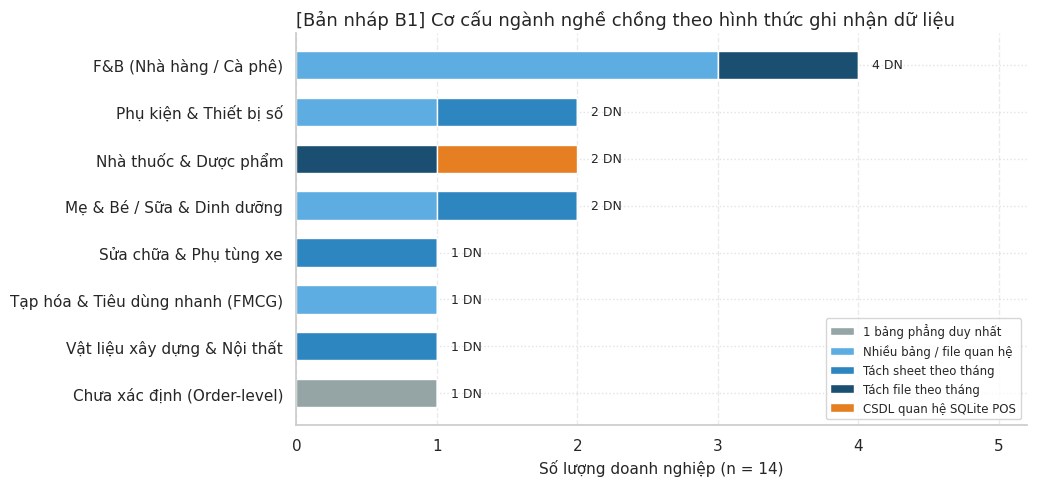

In [37]:
# Chuẩn bị bảng chéo giữa ngành nghề (industry) và hình thức ghi nhận (recording_format)
piv_fmt = catalog_14_df.pivot_table(
    index="industry",
    columns="recording_format",
    values="business_id",
    aggfunc="count",
    fill_value=0,
)

fmt_labels = {
    "single_flat_table": "1 bảng phẳng duy nhất",
    "multi_table_workbook_or_csv": "Nhiều bảng / file quan hệ",
    "monthly_split_sheets": "Tách sheet theo tháng",
    "monthly_split_files": "Tách file theo tháng",
    "relational_sqlite_pos": "CSDL quan hệ SQLite POS",
}
fmt_colors = ["#95A5A6", "#5DADE2", "#2E86C1", "#1B4F72", "#E67E22"]

for col in fmt_labels:
    if col not in piv_fmt.columns:
        piv_fmt[col] = 0

piv_fmt = piv_fmt[list(fmt_labels.keys())]
piv_fmt["total"] = piv_fmt.sum(axis=1)
piv_fmt = piv_fmt.sort_values("total", ascending=True)

fig, ax = plt.subplots(figsize=(10.5, 5.0))
y_pos = np.arange(len(piv_fmt))
left_acc = np.zeros(len(piv_fmt))

for col, c_hex in zip(fmt_labels.keys(), fmt_colors):
    vals = piv_fmt[col].values
    if vals.sum() > 0:
        ax.barh(y_pos, vals, left=left_acc, color=c_hex, height=0.6, label=fmt_labels[col])
        left_acc += vals

ax.set_yticks(y_pos)
ax.set_yticklabels(piv_fmt.index)
ax.set_xlim(0, piv_fmt["total"].max() + 1.2)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_xlabel("Số lượng doanh nghiệp (n = 14)")
ax.set_title("[Bản nháp B1] Cơ cấu ngành nghề chồng theo hình thức ghi nhận dữ liệu")
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
ax.legend(loc="lower right", frameon=True, fontsize=8.5)

for idx, tot in enumerate(piv_fmt["total"]):
    ax.text(tot + 0.1, idx, f"{int(tot)} DN", va="center", fontsize=9)

fig.tight_layout()
fig.savefig(PHASE1_FIGURES_DIR / "draft_t13a_b1_industry_format.png", dpi=130)
plt.show()


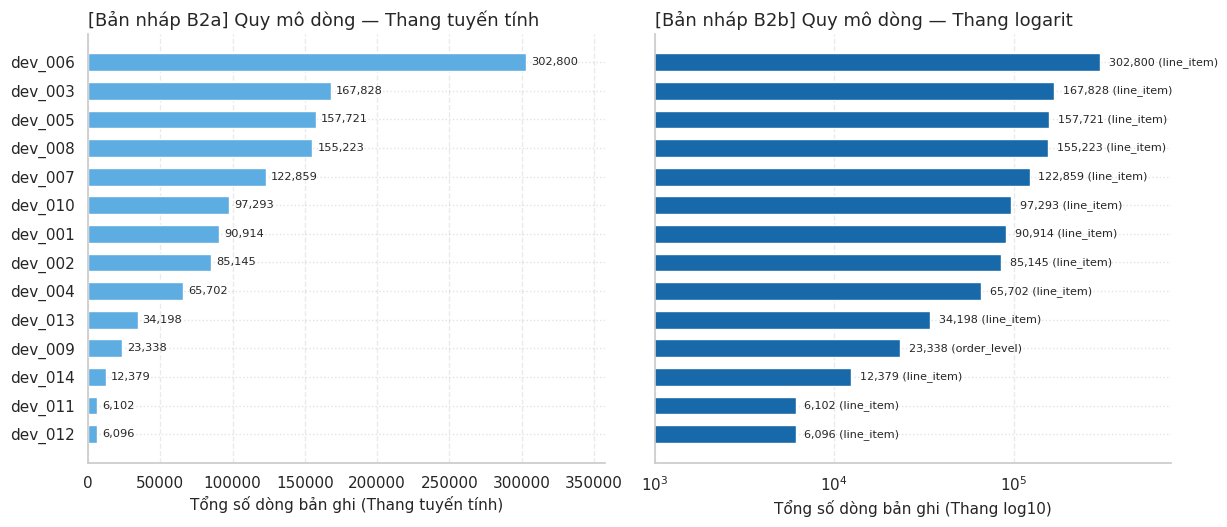

In [38]:
d_scale = catalog_14_df.sort_values("total_record_rows", ascending=True).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.4), sharey=True)

# Trái: Thang tuyến tính (Linear scale) — thấy rõ sự áp đảo của nhóm đầu
axes[0].barh(d_scale["business_id"], d_scale["total_record_rows"], color="#5DADE2", height=0.62)
axes[0].set_xlim(0, d_scale["total_record_rows"].max() * 1.18)
axes[0].set_xlabel("Tổng số dòng bản ghi (Thang tuyến tính)")
axes[0].set_title("[Bản nháp B2a] Quy mô dòng — Thang tuyến tính")
axes[0].grid(axis="x", linestyle="--", alpha=0.4)
for idx, r in enumerate(d_scale.itertuples()):
    axes[0].text(r.total_record_rows + 3500, idx, f"{int(r.total_record_rows):,}", va="center", fontsize=8.2)

# Phải: Thang logarit (Log scale) — quan sát rõ cả các DN quy mô nhỏ (~6k dòng)
axes[1].barh(d_scale["business_id"], d_scale["total_record_rows"], color=COLOR_ACCENT_BLUE, height=0.62)
axes[1].set_xscale("log")
axes[1].set_xlim(1e3, d_scale["total_record_rows"].max() * 2.5)
axes[1].set_xlabel("Tổng số dòng bản ghi (Thang log10)")
axes[1].set_title("[Bản nháp B2b] Quy mô dòng — Thang logarit")
axes[1].grid(axis="x", linestyle="--", alpha=0.4)
for idx, r in enumerate(d_scale.itertuples()):
    axes[1].text(r.total_record_rows * 1.12, idx, f"{int(r.total_record_rows):,} ({r.granularity})", va="center", fontsize=8.0)

fig.tight_layout()
fig.savefig(PHASE1_FIGURES_DIR / "draft_t13a_b2_scale_linear_vs_log.png", dpi=130)
plt.show()


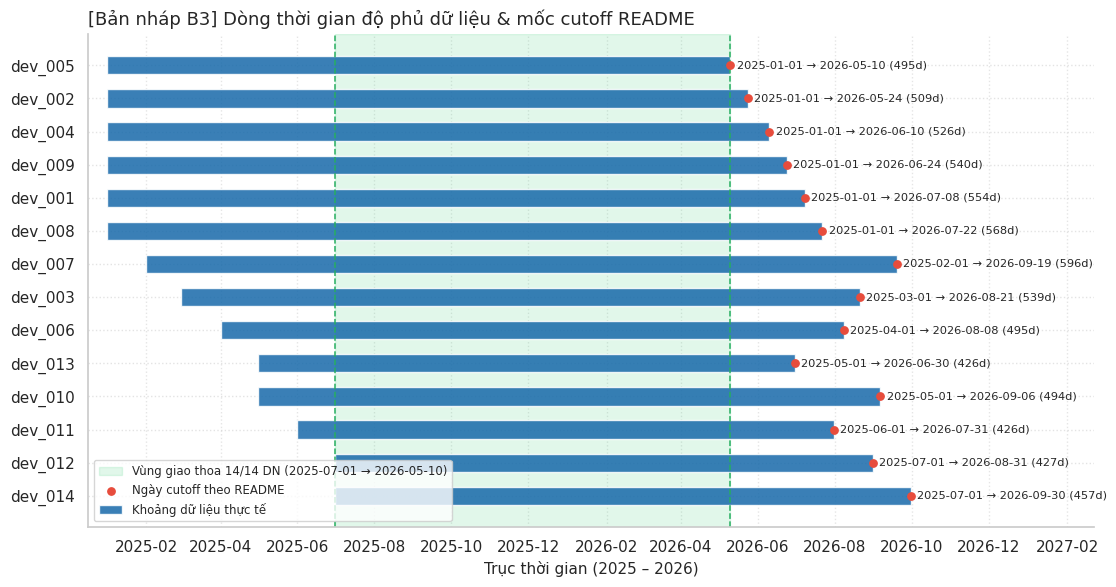

In [39]:
import matplotlib.dates as mdates

d_gantt = catalog_14_df.copy()
d_gantt["start_dt"] = pd.to_datetime(d_gantt["min_date"])
d_gantt["end_dt"] = pd.to_datetime(d_gantt["max_date"])
d_gantt["cutoff_dt"] = pd.to_datetime(d_gantt["readme_cutoff_date"])
d_gantt = d_gantt.sort_values(["start_dt", "end_dt"], ascending=[False, False]).reset_index(drop=True)

common_start = d_gantt["start_dt"].max()
common_end = d_gantt["end_dt"].min()

fig, ax = plt.subplots(figsize=(11.5, 6.0))

ax.axvspan(common_start, common_end, color="#2ECC71", alpha=0.14, label=f"Vùng giao thoa 14/14 DN ({common_start.strftime('%Y-%m-%d')} → {common_end.strftime('%Y-%m-%d')})")
ax.axvline(common_start, color="#27AE60", linestyle="--", linewidth=1.1)
ax.axvline(common_end, color="#27AE60", linestyle="--", linewidth=1.1)

y_idx = np.arange(len(d_gantt))
durations = (d_gantt["end_dt"] - d_gantt["start_dt"]).dt.days
ax.barh(y_idx, durations, left=d_gantt["start_dt"], height=0.55, color=COLOR_ACCENT_BLUE, alpha=0.85, label="Khoảng dữ liệu thực tế")

# Đánh dấu điểm cutoff README để kiểm chứng khớp 100%
ax.scatter(d_gantt["cutoff_dt"], y_idx, color="#E74C3C", zorder=5, s=28, label="Ngày cutoff theo README")

ax.set_yticks(y_idx)
ax.set_yticklabels(d_gantt["business_id"])
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.set_xlabel("Trục thời gian (2025 – 2026)")
ax.set_title("[Bản nháp B3] Dòng thời gian độ phủ dữ liệu & mốc cutoff README")
ax.grid(axis="x", linestyle=":", alpha=0.5)

for idx, r in enumerate(d_gantt.itertuples()):
    ax.text(r.end_dt + pd.Timedelta(days=5), idx, f"{r.min_date} → {r.max_date} ({int(r.span_days)}d)", va="center", fontsize=8.2)

ax.set_xlim(d_gantt["start_dt"].min() - pd.Timedelta(days=15), d_gantt["end_dt"].max() + pd.Timedelta(days=145))
ax.legend(loc="lower left", frameon=True, fontsize=8.5)

fig.tight_layout()
fig.savefig(PHASE1_FIGURES_DIR / "draft_t13a_b3_temporal_gantt.png", dpi=130)
plt.show()


In [40]:
chart_selection_eval = pd.DataFrame([
    {
        "chart_id": "Chart A (Ngành nghề × Mức độ chi tiết / Ghi nhận)",
        "source_draft": "Bản nháp B1 + T1.2a",
        "core_message": "14 DN trải trên 7 nhóm ngành (F&B chiếm nhiều nhất 4 DN); 13/14 ở cấp line_item, duy nhất dev_009 ở cấp order_level.",
        "redundancy_check": "Không trùng lặp — Thay thế biểu đồ đếm ngành đơn thuần bằng biểu đồ chồng chi tiết hơn.",
        "selected_for_t13b": "CHỌN (Tinh chỉnh thành Hình 1 của Hồi 1)",
    },
    {
        "chart_id": "Chart B (Quy mô bản ghi — Thang log vs Thang tuyến tính)",
        "source_draft": "Bản nháp B2a/B2b",
        "core_message": "Quy mô phân hóa ~50 lần (từ 6,096 dòng ở dev_012 lên 302,800 dòng ở dev_006); thang log giúp quan sát công bằng cả 2 nhóm.",
        "redundancy_check": "Không trùng lặp — Cung cấp ngữ cảnh trọng số mẫu trước khi phân tích từng doanh nghiệp.",
        "selected_for_t13b": "CHỌN (Bổ trợ hoặc ghép bảng tổng hợp)",
    },
    {
        "chart_id": "Chart C (Dòng thời gian độ phủ Gantt 2025–2026)",
        "source_draft": "Bản nháp B3",
        "core_message": "100% khớp ngày cutoff README; cửa sổ giao thoa chung của cả 14 DN là 2025-07-01 → 2026-05-10 (314 ngày).",
        "redundancy_check": "Không trùng lặp — Thiết lập khung thời gian chuẩn cho NB03.",
        "selected_for_t13b": "CHỌN (Tinh chỉnh thành Hình 2 của Hồi 1)",
    },
    {
        "chart_id": "Chart D (Ma trận hiện diện 8 chiều thuộc tính)",
        "source_draft": "T1.2b (feature_presence_matrix)",
        "core_message": "Phân tách rõ 8 DN Tier 1 (đa chiều) vs 5 DN Tier 2 (cơ bản) vs 1 DN Tier 3 (order-level).",
        "redundancy_check": "Giữ ở phần phụ lục kỹ thuật T1.2b để tránh quá tải thông tin ở Hồi 1.",
        "selected_for_t13b": "GIỮ Ở T1.2b",
    },
])

display(chart_selection_eval)


,chart_id,source_draft,core_message,redundancy_check,selected_for_t13b
0,Chart A (Ngành nghề × Mức độ chi tiết / Ghi nhận),Bản nháp B1 + T1.2a,"14 DN trải trên 7 nhóm ngành (F&B chiếm nhiều nhất 4 DN); 13/14 ở cấp line_item, duy nhất dev_009 ở cấp order_level.",Không trùng lặp — Thay thế biểu đồ đếm ngành đơn thuần bằng biểu đồ chồng chi tiết hơn.,CHỌN (Tinh chỉnh thành Hình 1 của Hồi 1)
1,Chart B (Quy mô bản ghi — Thang log vs Thang tuyến tính),Bản nháp B2a/B2b,"Quy mô phân hóa ~50 lần (từ 6,096 dòng ở dev_012 lên 302,800 dòng ở dev_006); thang log giúp quan sát công bằng cả 2 nhóm.",Không trùng lặp — Cung cấp ngữ cảnh trọng số mẫu trước khi phân tích từng doanh nghiệp.,CHỌN (Bổ trợ hoặc ghép bảng tổng hợp)
2,Chart C (Dòng thời gian độ phủ Gantt 2025–2026),Bản nháp B3,100% khớp ngày cutoff README; cửa sổ giao thoa chung của cả 14 DN là 2025-07-01 → 2026-05-10 (314 ngày).,Không trùng lặp — Thiết lập khung thời gian chuẩn cho NB03.,CHỌN (Tinh chỉnh thành Hình 2 của Hồi 1)
3,Chart D (Ma trận hiện diện 8 chiều thuộc tính),T1.2b (feature_presence_matrix),Phân tách rõ 8 DN Tier 1 (đa chiều) vs 5 DN Tier 2 (cơ bản) vs 1 DN Tier 3 (order-level).,Giữ ở phần phụ lục kỹ thuật T1.2b để tránh quá tải thông tin ở Hồi 1.,GIỮ Ở T1.2b


### Trực quan hóa


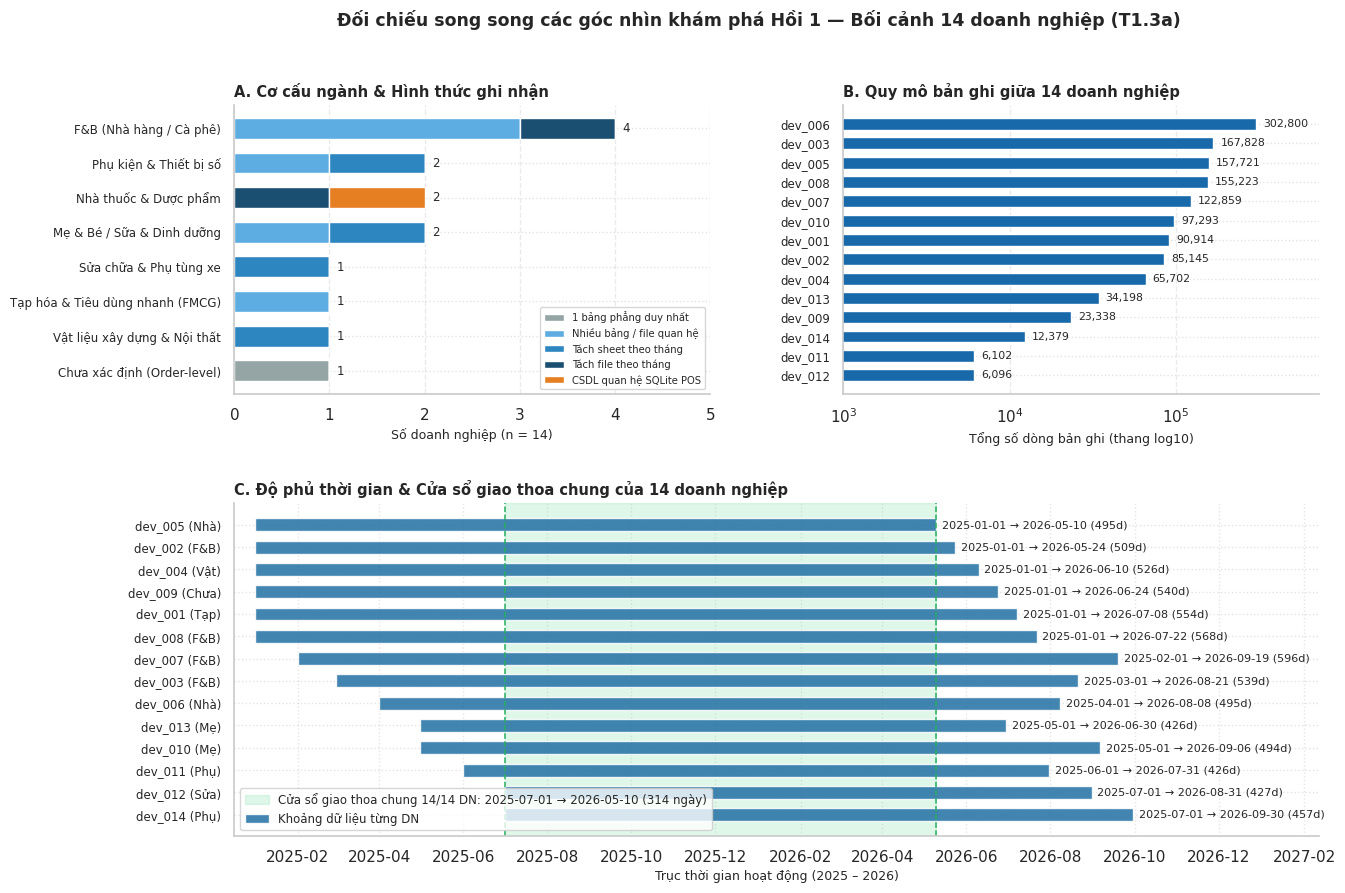

Đã lưu bảng đối chiếu khám phá T1.3a tại: C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\artifacts\guided_eda\phase1_dataset_discovery\figures\t13a_exploratory_panel.png


In [41]:
fig = plt.figure(figsize=(14, 9.5))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.15], hspace=0.35, wspace=0.28)

# --- Panel 1 (Trên - Trái): Cơ cấu ngành nghề & hình thức ghi nhận ---
ax1 = fig.add_subplot(gs[0, 0])
y_pos1 = np.arange(len(piv_fmt))
left_acc1 = np.zeros(len(piv_fmt))
for col, c_hex in zip(fmt_labels.keys(), fmt_colors):
    vals = piv_fmt[col].values
    if vals.sum() > 0:
        ax1.barh(y_pos1, vals, left=left_acc1, color=c_hex, height=0.6, label=fmt_labels[col])
        left_acc1 += vals
ax1.set_yticks(y_pos1)
ax1.set_yticklabels(piv_fmt.index, fontsize=8.5)
ax1.set_xlim(0, piv_fmt["total"].max() + 1.0)
ax1.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax1.set_xlabel("Số doanh nghiệp (n = 14)", fontsize=9)
ax1.set_title("A. Cơ cấu ngành & Hình thức ghi nhận", fontsize=10.5, fontweight="bold")
ax1.grid(axis="x", linestyle="--", alpha=0.4)
ax1.legend(loc="lower right", fontsize=7.2, frameon=True)
for idx, tot in enumerate(piv_fmt["total"]):
    ax1.text(tot + 0.08, idx, f"{int(tot)}", va="center", fontsize=8.5)

# --- Panel 2 (Trên - Phải): Quy mô số dòng bản ghi (thang log, bắt đầu từ 10^3) ---
ax2 = fig.add_subplot(gs[0, 1])
y_pos2 = np.arange(len(d_scale))
ax2.barh(y_pos2, d_scale["total_record_rows"], color=COLOR_ACCENT_BLUE, height=0.62)
ax2.set_xscale("log")
ax2.set_xlim(1e3, d_scale["total_record_rows"].max() * 2.4)
ax2.set_yticks(y_pos2)
ax2.set_yticklabels(d_scale["business_id"], fontsize=8.5)
ax2.set_xlabel("Tổng số dòng bản ghi (thang log10)", fontsize=9)
ax2.set_title("B. Quy mô bản ghi giữa 14 doanh nghiệp", fontsize=10.5, fontweight="bold")
ax2.grid(axis="x", linestyle="--", alpha=0.4)
for idx, r in enumerate(d_scale.itertuples()):
    ax2.text(r.total_record_rows * 1.1, idx, f"{int(r.total_record_rows):,}", va="center", fontsize=7.8)

# --- Panel 3 (Dưới - Toàn chiều ngang): Dòng thời gian độ phủ & Cửa sổ giao thoa chung ---
ax3 = fig.add_subplot(gs[1, :])
ax3.axvspan(
    common_start, common_end, color="#2ECC71", alpha=0.15,
    label=f"Cửa sổ giao thoa chung 14/14 DN: {common_start.strftime('%Y-%m-%d')} → {common_end.strftime('%Y-%m-%d')} ({(common_end - common_start).days + 1} ngày)"
)
ax3.axvline(common_start, color="#27AE60", linestyle="--", linewidth=1.1)
ax3.axvline(common_end, color="#27AE60", linestyle="--", linewidth=1.1)

y_pos3 = np.arange(len(d_gantt))
durations3 = (d_gantt["end_dt"] - d_gantt["start_dt"]).dt.days
ax3.barh(y_pos3, durations3, left=d_gantt["start_dt"], height=0.58, color="#2874A6", alpha=0.88, label="Khoảng dữ liệu từng DN")
ax3.set_yticks(y_pos3)
ax3.set_yticklabels([f"{r.business_id} ({r.industry.split(' ')[0]})" for r in d_gantt.itertuples()], fontsize=8.5)
ax3.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax3.set_xlabel("Trục thời gian hoạt động (2025 – 2026)", fontsize=9)
ax3.set_title("C. Độ phủ thời gian & Cửa sổ giao thoa chung của 14 doanh nghiệp", fontsize=10.5, fontweight="bold")
ax3.grid(axis="x", linestyle=":", alpha=0.5)
for idx, r in enumerate(d_gantt.itertuples()):
    ax3.text(r.end_dt + pd.Timedelta(days=4), idx, f"{r.min_date} → {r.max_date} ({int(r.span_days)}d)", va="center", fontsize=8.0)
ax3.set_xlim(d_gantt["start_dt"].min() - pd.Timedelta(days=15), d_gantt["end_dt"].max() + pd.Timedelta(days=135))
ax3.legend(loc="lower left", fontsize=8.5, frameon=True)

fig.suptitle("Đối chiếu song song các góc nhìn khám phá Hồi 1 — Bối cảnh 14 doanh nghiệp (T1.3a)", fontsize=12.5, fontweight="bold", y=0.98)

fig_t13a_panel = PHASE1_FIGURES_DIR / "t13a_exploratory_panel.png"
fig.savefig(fig_t13a_panel, dpi=150, bbox_inches="tight")
plt.show()
print("Đã lưu bảng đối chiếu khám phá T1.3a tại:", fig_t13a_panel)


### Kết quả & Nhận định

> **TODO (T1.3a):** Thành viên tự ghi nhận phát hiện dựa trên bằng chứng vừa chạy ở trên (không suy diễn vượt quá dữ liệu).

- **Các mẫu hình chính phát hiện từ biểu đồ nháp Hồi 1:** ...
- **Những điểm hạn chế trong biểu đồ nháp cần khắc phục ở `T1.3b` (nhãn chồng chéo, thiếu tiêu đề chủ động, màu sắc chưa có trọng tâm...):** ...


## Tác vụ T1.3b — Tinh chỉnh biểu đồ Giải thích Hồi 1 (Explanatory)

### Mục tiêu
Nâng cấp các biểu đồ trọng tâm của Hồi 1 từ dạng Khám phá sang Giải thích (Explanatory) theo chuẩn Cleveland–McGill và 5 hướng dẫn của Schwabish (*Show the data, Reduce clutter, Graphics + Text, Small multiples, Start with gray*).

### Câu hỏi khám phá
- Tiêu đề chủ động (*active title*) của mỗi biểu đồ Hồi 1 đã nêu bật được kết luận chính chưa?
- Đã loại bỏ nhiễu (viền thừa, lưới đậm, chú giải rời không cần thiết) và áp dụng nhấn màu trên nền xám chưa?
- Mỗi biểu đồ đã ghi đầy đủ đơn vị, cỡ mẫu (`n = 14 doanh nghiệp`), nguồn `DataMate public_test` và khoảng thời gian quan sát chưa?

### Các bước thực hiện

**Bước 1 — Kiểm tra mã hóa thị giác và quy tắc trung thực**
Rà soát lại từng biểu đồ Hồi 1 được chọn từ `T1.3a` về thang Cleveland–McGill, gốc trục 0 (với biểu đồ cột), không 3D, không hai trục y.

**Bước 2 — Tinh chỉnh biểu đồ 1 — Cơ cấu ngành nghề & Mức độ số hóa**
Áp dụng nền xám + màu nhấn, bỏ viền trên/phải (`sns.despine()`), gắn nhãn số trực tiếp lên thanh, viết tiêu đề chủ động và lưu vào `PHASE1_FIGURES_DIR`.

**Bước 3 — Tinh chỉnh biểu đồ 2 — Dòng thời gian độ phủ dữ liệu & Khoảng trống (2025–2026)**
Vẽ timeline độ phủ của 14 doanh nghiệp, làm nổi bật sự khác biệt ngày cutoff và các tháng thiếu dữ liệu bằng chú thích trực tiếp, lưu vào `PHASE1_FIGURES_DIR`.

**Bước 4 — Tinh chỉnh biểu đồ 3 — Phân bố quy mô & Mức độ chi tiết dữ liệu**
Trình bày quy mô dòng kèm nhãn cấp độ chi tiết (`granularity`), chú thích rõ đơn vị đếm và lưu vào `PHASE1_FIGURES_DIR`.

### Gợi ý phương pháp & Lưu ý
- Áp dụng quy trình 4 bước Chương 2 §2.7: (1) Vẽ bằng dữ liệu sạch → (2) Chuyển toàn bộ về màu xám (`#9AA5B1`) → (3) Tô màu nhấn cho nhóm cần làm nổi bật + gắn nhãn trực tiếp + viết tiêu đề chủ động → (4) Ghi chú nguồn/đơn vị/cỡ mẫu.
- Xuất các hình Hồi 1 vào `PHASE1_FIGURES_DIR` (`artifacts/guided_eda/phase1_dataset_discovery/figures/`) để Notebook 04 có thể kiểm định tập trung.

### Triển khai


In [42]:
visual_audit_df = pd.DataFrame([
    {
        "figure_name": "fig1_industry_digitization.png",
        "chart_type": "Biểu đồ cột ngang (Horizontal Bar)",
        "cleveland_mcgill_rank": "Hạng 1 — Vị trí dọc trục chung (Độ chính xác cao nhất)",
        "zero_baseline": "Đạt (x = 0)",
        "no_3d_no_dual_axis": "Đạt",
        "storytelling_design": "Nền xám (#9AA5B1) cho các ngành thông thường, tô màu nhấn (#1F618D) cho nhóm F&B chiếm tỷ trọng cao nhất (4/14 DN) + chú thích trực tiếp.",
    },
    {
        "figure_name": "fig2_temporal_coverage_story.png",
        "chart_type": "Biểu đồ đoạn thẳng theo thời gian (Timeline / Range Plot)",
        "cleveland_mcgill_rank": "Hạng 2 — Vị trí trên thang thời gian chung không thẳng hàng",
        "zero_baseline": "Không áp dụng (Trục thời gian liên tục 2025–2026)",
        "no_3d_no_dual_axis": "Đạt",
        "storytelling_design": "Nền xám (#9AA5B1) cho khoảng thời gian riêng lẻ, tô màu nhấn cho vùng giao thoa chung 14/14 DN (314 ngày) và đánh dấu mốc cutoff lệch nhau tới 143 ngày.",
    },
    {
        "figure_name": "fig3_scale_and_granularity.png",
        "chart_type": "Biểu đồ chấm / thanh ngang thang log (Dot / Bar Plot)",
        "cleveland_mcgill_rank": "Hạng 1 — Vị trí dọc trục chung (Thang log10 ghi chú rõ đơn vị)",
        "zero_baseline": "Ghi chú rõ mốc xuất phát 10^3 dòng (do chênh lệch ~50 lần)",
        "no_3d_no_dual_axis": "Đạt",
        "storytelling_design": "Phân tách màu giữa cấp dòng hàng (line_item, 13 DN) và màu cảnh báo (#D35400) cho duy nhất dev_009 ở cấp hóa đơn tổng (order_level).",
    },
])

display(visual_audit_df)


,figure_name,chart_type,cleveland_mcgill_rank,zero_baseline,no_3d_no_dual_axis,storytelling_design
0,fig1_industry_digitization.png,Biểu đồ cột ngang (Horizontal Bar),Hạng 1 — Vị trí dọc trục chung (Độ chính xác cao nhất),Đạt (x = 0),Đạt,"Nền xám (#9AA5B1) cho các ngành thông thường, tô màu nhấn (#1F618D) cho nhóm F&B chiếm tỷ trọng cao nhất (4/14 DN) + chú thích trực tiếp."
1,fig2_temporal_coverage_story.png,Biểu đồ đoạn thẳng theo thời gian (Timeline / Range Plot),Hạng 2 — Vị trí trên thang thời gian chung không thẳng hàng,Không áp dụng (Trục thời gian liên tục 2025–2026),Đạt,"Nền xám (#9AA5B1) cho khoảng thời gian riêng lẻ, tô màu nhấn cho vùng giao thoa chung 14/14 DN (314 ngày) và đánh dấu mốc cutoff lệch nh..."
2,fig3_scale_and_granularity.png,Biểu đồ chấm / thanh ngang thang log (Dot / Bar Plot),Hạng 1 — Vị trí dọc trục chung (Thang log10 ghi chú rõ đơn vị),Ghi chú rõ mốc xuất phát 10^3 dòng (do chênh lệch ~50 lần),Đạt,"Phân tách màu giữa cấp dòng hàng (line_item, 13 DN) và màu cảnh báo (#D35400) cho duy nhất dev_009 ở cấp hóa đơn tổng (order_level)."


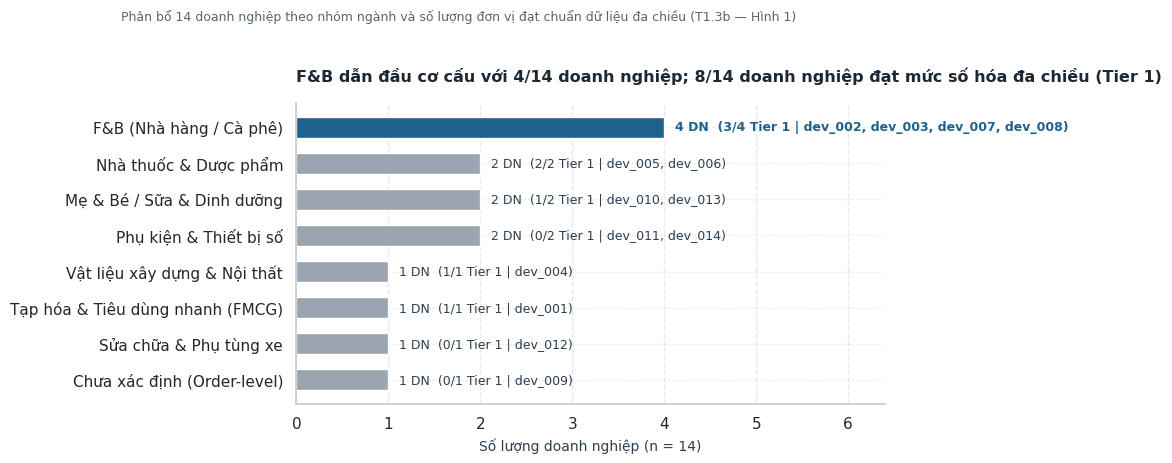

Đã lưu Hình 1 tại: C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\artifacts\guided_eda\phase1_dataset_discovery\figures\fig1_industry_digitization.png


In [43]:
import seaborn as sns

GRAY_MUTED = "#9AA5B1"
ACCENT_PRIMARY = "#1F618D"
ACCENT_WARN = "#D35400"

# Tính số lượng DN và số DN đạt mức số hóa cao (Tier 1 đa chiều) theo từng ngành
ind_summary = (
    catalog_14_df.groupby("industry", as_index=False)
    .agg(
        n_biz=("business_id", "count"),
        n_tier1=("comparability_tier", lambda s: sum("Tier 1" in x for x in s)),
        biz_list=("business_id", lambda s: ", ".join(s)),
    )
    .sort_values(["n_biz", "n_tier1"], ascending=[True, True])
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(10.2, 5.0))

# Bước 1 & 2: Vẽ toàn bộ bằng màu xám #9AA5B1, tô màu nhấn cho nhóm F&B (nhóm lớn nhất)
colors_bar = [ACCENT_PRIMARY if r.industry.startswith("F&B") else GRAY_MUTED for r in ind_summary.itertuples()]
bars = ax.barh(ind_summary["industry"], ind_summary["n_biz"], color=colors_bar, height=0.58)

ax.set_xlim(0, ind_summary["n_biz"].max() + 2.4)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_xlabel("Số lượng doanh nghiệp (n = 14)", fontsize=10, color="#2C3E50")
ax.set_ylabel("")

# Tiêu đề chủ động (Action Title) nêu thẳng phát hiện chính
ax.set_title(
    "F&B dẫn đầu cơ cấu với 4/14 doanh nghiệp; 8/14 doanh nghiệp đạt mức số hóa đa chiều (Tier 1)",
    fontsize=11.5, fontweight="bold", loc="left", pad=16, color="#1C2833"
)
plt.suptitle(
    "Phân bổ 14 doanh nghiệp theo nhóm ngành và số lượng đơn vị đạt chuẩn dữ liệu đa chiều (T1.3b — Hình 1)",
    fontsize=9, color="#566573", x=0.125, y=0.92, ha="left"
)

sns.despine(top=True, right=True)
ax.grid(axis="x", linestyle="--", alpha=0.35, color="#BDC3C7")
ax.set_axisbelow(True)

# Gắn nhãn trực tiếp lên thanh
for idx, r in enumerate(ind_summary.itertuples()):
    txt_color = ACCENT_PRIMARY if r.industry.startswith("F&B") else "#2C3E50"
    ax.text(
        r.n_biz + 0.12, idx,
        f"{r.n_biz} DN  ({r.n_tier1}/{r.n_biz} Tier 1 | {r.biz_list})",
        va="center", fontsize=9, fontweight="bold" if r.industry.startswith("F&B") else "normal",
        color=txt_color
    )

fig.tight_layout(rect=[0, 0, 1, 0.90])
fig1_path = PHASE1_FIGURES_DIR / "fig1_industry_digitization.png"
fig.savefig(fig1_path, dpi=180)
plt.show()
print("Đã lưu Hình 1 tại:", fig1_path)


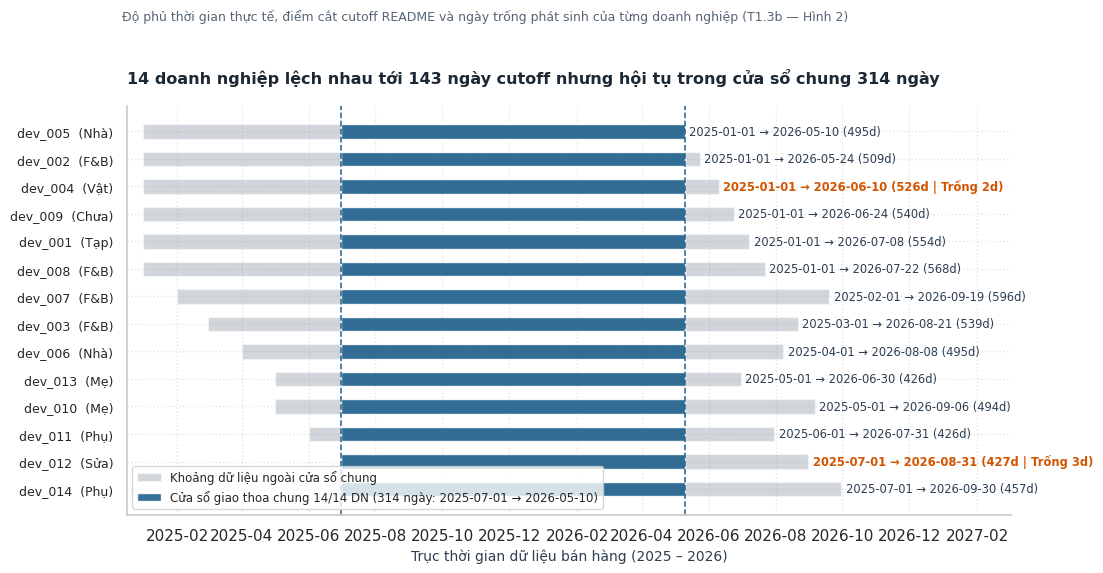

Đã lưu Hình 2 tại: C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\artifacts\guided_eda\phase1_dataset_discovery\figures\fig2_temporal_coverage_story.png


In [44]:
import matplotlib.dates as mdates

d_tl = catalog_14_df.copy()
d_tl["start_dt"] = pd.to_datetime(d_tl["min_date"])
d_tl["end_dt"] = pd.to_datetime(d_tl["max_date"])
d_tl = d_tl.sort_values(["start_dt", "end_dt"], ascending=[False, False]).reset_index(drop=True)

common_start = d_tl["start_dt"].max()  # 2025-07-01
common_end = d_tl["end_dt"].min()      # 2026-05-10
common_days = (common_end - common_start).days + 1
cutoff_spread = (d_tl["end_dt"].max() - d_tl["end_dt"].min()).days

fig, ax = plt.subplots(figsize=(11.2, 6.2))

# Nền xám cho toàn bộ khoảng thời gian riêng lẻ của từng DN
y_idx = np.arange(len(d_tl))
full_durations = (d_tl["end_dt"] - d_tl["start_dt"]).dt.days
ax.barh(
    y_idx, full_durations, left=d_tl["start_dt"],
    height=0.52, color=GRAY_MUTED, alpha=0.45,
    label="Khoảng dữ liệu ngoài cửa sổ chung"
)

# Tô màu nhấn cho phần nằm trong cửa sổ giao thoa chung của cả 14/14 DN
overlap_duration = (common_end - common_start).days
ax.barh(
    y_idx, [overlap_duration] * len(d_tl), left=[common_start] * len(d_tl),
    height=0.52, color=ACCENT_PRIMARY, alpha=0.9,
    label=f"Cửa sổ giao thoa chung 14/14 DN ({common_days} ngày: 2025-07-01 → 2026-05-10)"
)

ax.axvline(common_start, color=ACCENT_PRIMARY, linestyle="--", linewidth=1.1)
ax.axvline(common_end, color=ACCENT_PRIMARY, linestyle="--", linewidth=1.1)

# Đánh dấu các doanh nghiệp có ngày nghỉ/khoảng trống nhỏ (coverage_ratio < 1.0)
for idx, r in enumerate(d_tl.itertuples()):
    gap_note = f" | Trống {int(r.span_days - r.active_days)}d" if r.coverage_ratio < 1.0 else ""
    ax.text(
        r.end_dt + pd.Timedelta(days=4), idx,
        f"{r.min_date} → {r.max_date} ({int(r.span_days)}d{gap_note})",
        va="center", fontsize=8.3,
        color=ACCENT_WARN if r.coverage_ratio < 1.0 else "#2C3E50",
        fontweight="bold" if r.coverage_ratio < 1.0 else "normal"
    )

ax.set_yticks(y_idx)
ax.set_yticklabels([f"{r.business_id}  ({r.industry.split(' ')[0]})" for r in d_tl.itertuples()], fontsize=9)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.set_xlabel("Trục thời gian dữ liệu bán hàng (2025 – 2026)", fontsize=10, color="#2C3E50")

ax.set_title(
    f"14 doanh nghiệp lệch nhau tới {cutoff_spread} ngày cutoff nhưng hội tụ trong cửa sổ chung 314 ngày",
    fontsize=11.5, fontweight="bold", loc="left", pad=16, color="#1C2833"
)
plt.suptitle(
    "Độ phủ thời gian thực tế, điểm cắt cutoff README và ngày trống phát sinh của từng doanh nghiệp (T1.3b — Hình 2)",
    fontsize=9, color="#566573", x=0.115, y=0.92, ha="left"
)

sns.despine(top=True, right=True)
ax.grid(axis="x", linestyle=":", alpha=0.45, color="#BDC3C7")
ax.set_axisbelow(True)
ax.set_xlim(d_tl["start_dt"].min() - pd.Timedelta(days=15), d_tl["end_dt"].max() + pd.Timedelta(days=155))
ax.legend(loc="lower left", frameon=True, fontsize=8.5)

fig.tight_layout(rect=[0, 0, 1, 0.90])
fig2_path = PHASE1_FIGURES_DIR / "fig2_temporal_coverage_story.png"
fig.savefig(fig2_path, dpi=180)
plt.show()
print("Đã lưu Hình 2 tại:", fig2_path)


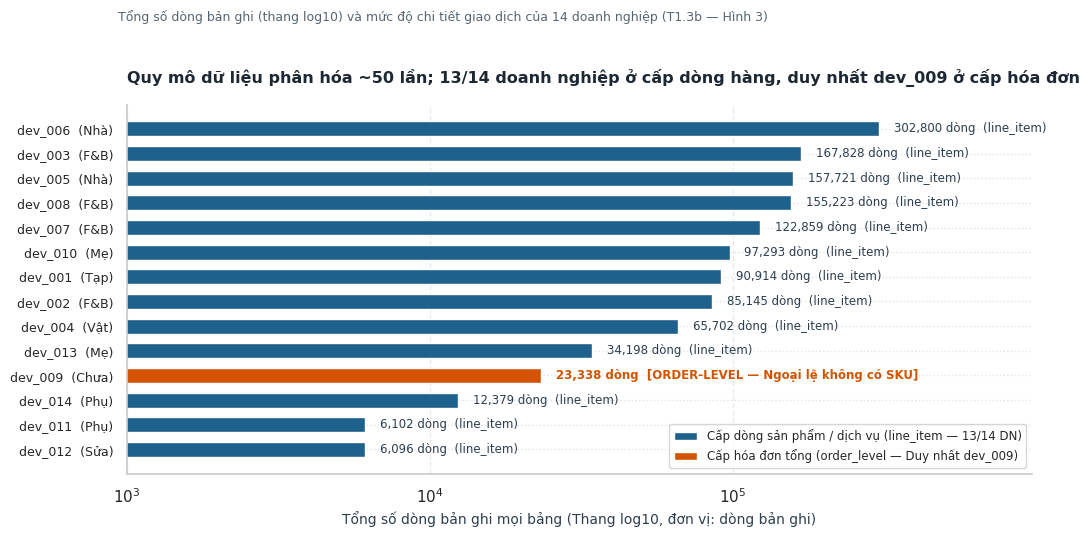

Đã lưu Hình 3 tại: C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\artifacts\guided_eda\phase1_dataset_discovery\figures\fig3_scale_and_granularity.png


In [45]:
d_gran = catalog_14_df.sort_values("total_record_rows", ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10.8, 5.8))

y_pos = np.arange(len(d_gran))
# Màu nhấn xanh cho line_item, màu cam cảnh báo cho ngoại lệ duy nhất order_level (dev_009)
bar_colors = [ACCENT_WARN if r.granularity == "order_level" else ACCENT_PRIMARY for r in d_gran.itertuples()]

ax.barh(y_pos, d_gran["total_record_rows"], color=bar_colors, height=0.6)
ax.set_xscale("log")
ax.set_xlim(1e3, d_gran["total_record_rows"].max() * 3.2)

ax.set_yticks(y_pos)
ax.set_yticklabels([f"{r.business_id}  ({r.industry.split(' ')[0]})" for r in d_gran.itertuples()], fontsize=9)
ax.set_xlabel("Tổng số dòng bản ghi mọi bảng (Thang log10, đơn vị: dòng bản ghi)", fontsize=10, color="#2C3E50")

# Chú thích trực tiếp từng thanh kèm nhãn granularity
for idx, r in enumerate(d_gran.itertuples()):
    is_order = r.granularity == "order_level"
    lbl = f"{int(r.total_record_rows):,} dòng  [ORDER-LEVEL — Ngoại lệ không có SKU]" if is_order else f"{int(r.total_record_rows):,} dòng  (line_item)"
    ax.text(
        r.total_record_rows * 1.12, idx, lbl,
        va="center", fontsize=8.5,
        fontweight="bold" if is_order else "normal",
        color=ACCENT_WARN if is_order else "#2C3E50"
    )

# Legend thủ công rõ ràng
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=ACCENT_PRIMARY, label="Cấp dòng sản phẩm / dịch vụ (line_item — 13/14 DN)"),
    Patch(facecolor=ACCENT_WARN, label="Cấp hóa đơn tổng (order_level — Duy nhất dev_009)"),
]
ax.legend(handles=legend_handles, loc="lower right", frameon=True, fontsize=8.5)

ax.set_title(
    "Quy mô dữ liệu phân hóa ~50 lần; 13/14 doanh nghiệp ở cấp dòng hàng, duy nhất dev_009 ở cấp hóa đơn",
    fontsize=11.5, fontweight="bold", loc="left", pad=16, color="#1C2833"
)
plt.suptitle(
    "Tổng số dòng bản ghi (thang log10) và mức độ chi tiết giao dịch của 14 doanh nghiệp (T1.3b — Hình 3)",
    fontsize=9, color="#566573", x=0.115, y=0.92, ha="left"
)

sns.despine(top=True, right=True)
ax.grid(axis="x", linestyle="--", alpha=0.35, color="#BDC3C7")
ax.set_axisbelow(True)

fig.tight_layout(rect=[0, 0, 1, 0.90])
fig3_path = PHASE1_FIGURES_DIR / "fig3_scale_and_granularity.png"
fig.savefig(fig3_path, dpi=180)
plt.show()
print("Đã lưu Hình 3 tại:", fig3_path)


### Trực quan hóa


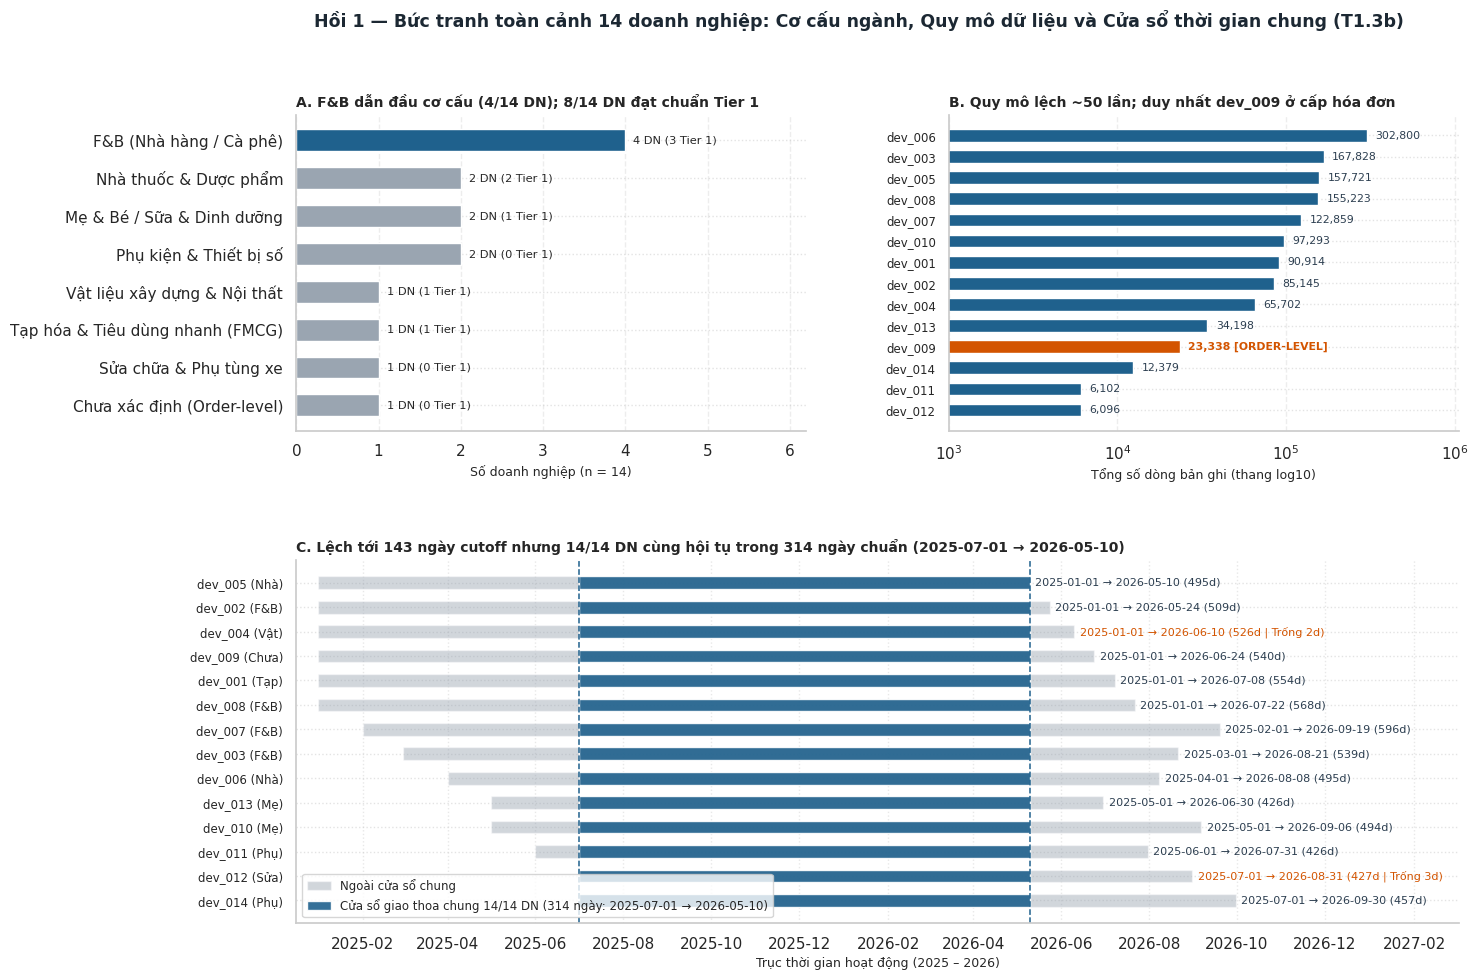

Đã lưu bảng tổng hợp giải thích Hồi 1 tại: C:\Users\teteb\Desktop\pythoncode\data-visualization-uth\artifacts\guided_eda\phase1_dataset_discovery\figures\t13b_explanatory_summary_panel.png


In [46]:
fig = plt.figure(figsize=(15, 10.5))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.15], hspace=0.38, wspace=0.28)

# --- Panel A (Trên - Trái): Cơ cấu ngành nghề & Tier 1 ---
ax_a = fig.add_subplot(gs[0, 0])
c_a = [ACCENT_PRIMARY if r.industry.startswith("F&B") else GRAY_MUTED for r in ind_summary.itertuples()]
ax_a.barh(ind_summary["industry"], ind_summary["n_biz"], color=c_a, height=0.58)
ax_a.set_xlim(0, ind_summary["n_biz"].max() + 2.2)
ax_a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax_a.set_xlabel("Số doanh nghiệp (n = 14)", fontsize=9)
ax_a.set_title("A. F&B dẫn đầu cơ cấu (4/14 DN); 8/14 DN đạt chuẩn Tier 1", fontsize=10, fontweight="bold", loc="left")
sns.despine(ax=ax_a, top=True, right=True)
ax_a.grid(axis="x", linestyle="--", alpha=0.35)
for idx, r in enumerate(ind_summary.itertuples()):
    ax_a.text(r.n_biz + 0.1, idx, f"{r.n_biz} DN ({r.n_tier1} Tier 1)", va="center", fontsize=8.2)

# --- Panel B (Trên - Phải): Quy mô dòng & Mức độ chi tiết ---
ax_b = fig.add_subplot(gs[0, 1])
c_b = [ACCENT_WARN if r.granularity == "order_level" else ACCENT_PRIMARY for r in d_gran.itertuples()]
ax_b.barh(np.arange(len(d_gran)), d_gran["total_record_rows"], color=c_b, height=0.6)
ax_b.set_xscale("log")
ax_b.set_xlim(1e3, d_gran["total_record_rows"].max() * 3.5)
ax_b.set_yticks(np.arange(len(d_gran)))
ax_b.set_yticklabels(d_gran["business_id"], fontsize=8.5)
ax_b.set_xlabel("Tổng số dòng bản ghi (thang log10)", fontsize=9)
ax_b.set_title("B. Quy mô lệch ~50 lần; duy nhất dev_009 ở cấp hóa đơn", fontsize=10, fontweight="bold", loc="left")
sns.despine(ax=ax_b, top=True, right=True)
ax_b.grid(axis="x", linestyle="--", alpha=0.35)
for idx, r in enumerate(d_gran.itertuples()):
    tag = " [ORDER-LEVEL]" if r.granularity == "order_level" else ""
    ax_b.text(r.total_record_rows * 1.12, idx, f"{int(r.total_record_rows):,}{tag}", va="center", fontsize=7.8,
              color=ACCENT_WARN if r.granularity == "order_level" else "#2C3E50",
              fontweight="bold" if r.granularity == "order_level" else "normal")

# --- Panel C (Dưới - Toàn chiều ngang): Dòng thời gian độ phủ & Cửa sổ chung ---
ax_c = fig.add_subplot(gs[1, :])
ax_c.barh(y_idx, full_durations, left=d_tl["start_dt"], height=0.52, color=GRAY_MUTED, alpha=0.45, label="Ngoài cửa sổ chung")
ax_c.barh(y_idx, [overlap_duration] * len(d_tl), left=[common_start] * len(d_tl), height=0.52, color=ACCENT_PRIMARY, alpha=0.9,
          label=f"Cửa sổ giao thoa chung 14/14 DN ({common_days} ngày: 2025-07-01 → 2026-05-10)")
ax_c.axvline(common_start, color=ACCENT_PRIMARY, linestyle="--", linewidth=1.1)
ax_c.axvline(common_end, color=ACCENT_PRIMARY, linestyle="--", linewidth=1.1)
for idx, r in enumerate(d_tl.itertuples()):
    gap_note = f" | Trống {int(r.span_days - r.active_days)}d" if r.coverage_ratio < 1.0 else ""
    ax_c.text(r.end_dt + pd.Timedelta(days=4), idx, f"{r.min_date} → {r.max_date} ({int(r.span_days)}d{gap_note})",
              va="center", fontsize=8.0, color=ACCENT_WARN if r.coverage_ratio < 1.0 else "#2C3E50")
ax_c.set_yticks(y_idx)
ax_c.set_yticklabels([f"{r.business_id} ({r.industry.split(' ')[0]})" for r in d_tl.itertuples()], fontsize=8.5)
ax_c.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax_c.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax_c.set_xlabel("Trục thời gian hoạt động (2025 – 2026)", fontsize=9)
ax_c.set_title(f"C. Lệch tới {cutoff_spread} ngày cutoff nhưng 14/14 DN cùng hội tụ trong 314 ngày chuẩn (2025-07-01 → 2026-05-10)",
               fontsize=10, fontweight="bold", loc="left")
sns.despine(ax=ax_c, top=True, right=True)
ax_c.grid(axis="x", linestyle=":", alpha=0.45)
ax_c.set_xlim(d_tl["start_dt"].min() - pd.Timedelta(days=15), d_tl["end_dt"].max() + pd.Timedelta(days=155))
ax_c.legend(loc="lower left", frameon=True, fontsize=8.5)

fig.suptitle(
    "Hồi 1 — Bức tranh toàn cảnh 14 doanh nghiệp: Cơ cấu ngành, Quy mô dữ liệu và Cửa sổ thời gian chung (T1.3b)",
    fontsize=12.5, fontweight="bold", y=0.98, color="#1C2833"
)

summary_panel_path = PHASE1_FIGURES_DIR / "t13b_explanatory_summary_panel.png"
fig.savefig(summary_panel_path, dpi=180, bbox_inches="tight")
plt.show()
print("Đã lưu bảng tổng hợp giải thích Hồi 1 tại:", summary_panel_path)


### Kết quả & Nhận định

> **TODO (T1.3b):** Thành viên tự ghi nhận phát hiện dựa trên bằng chứng vừa chạy ở trên (không suy diễn vượt quá dữ liệu).

- **Thông điệp cốt lõi của Hồi 1 (*Bối cảnh*):** ...
- **Danh sách tệp biểu đồ Hồi 1 trong `PHASE1_FIGURES_DIR` sẵn sàng chuyển qua cổng kiểm định `T4.1a`:** ...


## 05. Tổng kết giai đoạn & Bàn giao

> **TODO (Thành viên phụ trách Giai đoạn 1):** Điền đầy đủ bảng tổng kết sau khi hoàn thành `T1.0`–`T1.3b`.

- **Những công việc đã thực hiện:**
  - [ ] `T1.0`: Xác nhận cấu hình chỉ đọc `public_test` và cơ chế chặn `questions.jsonl` / `train`.
  - [ ] `T1.1a`: Đọc và trích xuất metadata từ đủ 14 tệp `README.md` -> `readme_metadata.csv`.
  - [ ] `T1.1b`: Kiểm kê toàn bộ tệp `.csv`, `.xlsx` (mọi sheet), `.sqlite` -> `objects_inventory.csv`, `file_inventory.csv`.
  - [ ] `T1.1c`: Trích xuất `min_date`–`max_date`, ngày cutoff và khoảng trống -> `temporal_coverage.csv`.
  - [ ] `T1.2a`: Phân loại và kiểm chứng ngành nghề -> `industry_classification.csv`.
  - [ ] `T1.2b`: Gắn nhãn mức độ chi tiết, số hóa và hoàn thiện `catalog_14.csv`.
  - [ ] `T1.3a`–`T1.3b`: Dựng và tinh chỉnh bộ biểu đồ Giải thích Hồi 1 tại `PHASE1_FIGURES_DIR`.
- **Những phát hiện chính của Hồi 1:**
  - ...
- **Các vấn đề còn tồn tại / Cần lưu ý:**
  - ...
- **Giới hạn của kết quả:**
  - ...
- **Đầu ra bàn giao cho Giai đoạn 2 (`02_business_eda.ipynb`) và Giai đoạn 3 (`03_cross_business_eda.ipynb`):**
  - `artifacts/guided_eda/phase1_dataset_discovery/tables/catalog_14.csv`
  - `artifacts/guided_eda/phase1_dataset_discovery/figures/`
